# ICU Mortality Prediction & Constraint-Aware Counterfactual Explanations

**Dataset:** WiDS Datathon 2020 ICU cohort · **Target:** `hospital_death`

**Research question:** Can gradient-guided counterfactual explanations identify lower-cost, plausible and stable changes in patient feature profiles that alter a frozen ICU mortality model's predicted risk, compared with random-feature and greedy single-feature search?

> These are model-based counterfactual explanations, not clinical recourse or treatment recommendations. Changing a model input does not establish that changing a physiological variable would change a patient's actual outcome.

### Locked experimental protocol
1. Preserve the stratified 70/15/15 split (`random_state=42`).
2. Benchmark Logistic Regression, Random Forest and a compact MLP with a small, predeclared search budget.
3. Select the final model using validation PR-AUC only.
4. Select the operating threshold using validation data only.
5. Evaluate the frozen model on test data once. Never select a model using test metrics.
6. Compare gradient-guided, random-feature and greedy single-feature search on identical held-out test cases.
7. Evaluate success, normalized cost, constraint consistency, nearest-neighbour plausibility and seed stability.
8. Include failures in all denominators and export the full audit trail.

## 1. Environment and configuration

In [ ]:
# If required:
# %pip install -q pandas numpy scikit-learn matplotlib torch

import os, json, time, random, platform, sys, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
    log_loss, precision_recall_curve, f1_score, confusion_matrix)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors

try:
    import torch
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_AVAILABLE = True
except Exception as e:
    TORCH_AVAILABLE = False
    print("PyTorch unavailable:", repr(e))

SEED = 42
DATA_PATH = Path("/content/training_v2.csv")
OUT = Path("/content/icu_counterfactual_outputs")
OUT.mkdir(parents=True, exist_ok=True)
N_CF_CASES = 300
CF_MAX_FEATURES = 5
CF_MAX_STEPS = 40
CF_TARGET_MARGIN = 0.02
CF_EVAL_BUDGET = 500
BOOTSTRAP_REPS = 1000
STABILITY_SEEDS = [11, 29, 47]
DEVICE = "cuda" if TORCH_AVAILABLE and torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
if TORCH_AVAILABLE:
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
print("Python:", sys.version, "| Device:", DEVICE)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0] | Device: cpu


### 1.1 Load and audit the WiDS table

In [ ]:
TARGET = "hospital_death"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Set DATA_PATH to your WiDS CSV. Missing: {DATA_PATH.resolve()}")
df = pd.read_csv(DATA_PATH, low_memory=False)
assert TARGET in df.columns, f"Missing target: {TARGET}"
y = pd.to_numeric(df[TARGET], errors="coerce")
valid = y.notna() & y.isin([0, 1])
df = df.loc[valid].copy()
y = y.loc[valid].astype(int)
print("Shape:", df.shape, "| Mortality prevalence:", y.mean())
display(df.head())
display(y.value_counts().rename("count").to_frame())

Shape: (91713, 186) | Mortality prevalence: 0.08630183289173836


,encounter_id,patient_id,hospital_id,hospital_death,age,bmi,elective_surgery,ethnicity,gender,height,...,aids,cirrhosis,diabetes_mellitus,hepatic_failure,immunosuppression,leukemia,lymphoma,solid_tumor_with_metastasis,apache_3j_bodysystem,apache_2_bodysystem
0,66154,25312,118,0,68.0,22.73,0,Caucasian,M,180.3,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Sepsis,Cardiovascular
1,114252,59342,81,0,77.0,27.42,0,Caucasian,F,160.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Respiratory,Respiratory
2,119783,50777,118,0,25.0,31.95,0,Caucasian,F,172.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Metabolic,Metabolic
3,79267,46918,118,0,81.0,22.64,1,Caucasian,F,165.1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Cardiovascular,Cardiovascular
4,92056,34377,33,0,19.0,NaN,0,Caucasian,M,188.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Trauma,Trauma


,count
hospital_death,
0,83798
1,7915


## 2. Predictor definition and leakage exclusions
Identifiers and outcome-derived scores are excluded explicitly. No date transformations or temporal safeguards are assumed.

In [ ]:
EXCLUDE = [
    TARGET, "encounter_id", "patient_id", "readmission_status", "pred",
    "hospital_id", "icu_id", "apache_4a_hospital_death_prob",
    "apache_4a_icu_death_prob"
]
excluded_present = [c for c in EXCLUDE if c in df.columns]
X = df.drop(columns=excluded_present, errors="ignore").copy()
all_missing = X.columns[X.isna().all()].tolist()
constant = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=list(set(all_missing + constant)), errors="ignore")
for c in X.columns:
    if pd.api.types.is_bool_dtype(X[c]):
        X[c] = X[c].astype("Int64")
print("Rows:", len(X), "Features:", X.shape[1])
print("Excluded:", excluded_present, "All-missing:", all_missing, "Constant:", constant)

Rows: 91713 Features: 178
Excluded: ['hospital_death', 'encounter_id', 'patient_id', 'readmission_status', 'hospital_id', 'icu_id', 'apache_4a_hospital_death_prob', 'apache_4a_icu_death_prob'] All-missing: [] Constant: []


## 3. Preserve the original 70/15/15 split
This is the primary split. If patients have multiple encounters, encounter-level random splitting may create patient overlap; audit and report it rather than silently changing the requested split.

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)
display(pd.DataFrame({
    "split": ["train", "validation", "test"],
    "n": [len(y_train), len(y_val), len(y_test)],
    "deaths": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "prevalence": [y_train.mean(), y_val.mean(), y_test.mean()]
}))
if "patient_id" in df.columns:
    groups = {s: set(df.loc[idx, "patient_id"].dropna()) for s, idx in
              [("train", X_train.index), ("validation", X_val.index), ("test", X_test.index)]}
    print("Patient overlap train/validation:", len(groups["train"] & groups["validation"]))
    print("Patient overlap train/test:", len(groups["train"] & groups["test"]))
    print("Patient overlap validation/test:", len(groups["validation"] & groups["test"]))
else:
    print("patient_id not available; patient-overlap audit skipped.")

,split,n,deaths,prevalence
0,train,64199,5540,0.086294
1,validation,13757,1188,0.086356
2,test,13757,1187,0.086283


Patient overlap train/validation: 0
Patient overlap train/test: 0
Patient overlap validation/test: 0


## 4. Train-only preprocessing
Numerical features: median imputation, missingness indicators and standardization. Categorical features: mode imputation and one-hot encoding. The same fitted transformation is used for all models.

In [ ]:
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder)
    ]), cat_cols)
], remainder="drop", verbose_feature_names_out=False)
Xtr = np.asarray(preprocessor.fit_transform(X_train), dtype=np.float32)
Xva = np.asarray(preprocessor.transform(X_val), dtype=np.float32)
Xte = np.asarray(preprocessor.transform(X_test), dtype=np.float32)
print(Xtr.shape, Xva.shape, Xte.shape)

(64199, 397) (13757, 397) (13757, 397)


## 5. Comparable model benchmark
Each family gets a small predeclared search budget. This is a controlled baseline comparison, not exhaustive tuning.

In [196]:

# Preserve baseline results before replacing the models
baseline_models = models.copy()
baseline_val_probs = val_probs.copy()
baseline_histories = mlp_histories.copy()

def metric_row(name, yt, p):
    p = np.clip(np.asarray(p), 1e-7, 1-1e-7)
    return {
        "candidate": name,
        "ROC_AUC": roc_auc_score(yt, p),
        "PR_AUC": average_precision_score(yt, p),
        "Brier": brier_score_loss(yt, p),
        "LogLoss": log_loss(yt, p)
    }

models, val_probs, mlp_histories = {}, {}, {}

# Logistic Regression (unchanged)
for c in [0.1, 1.0]:
    name = f"LogisticRegression_C{c}"
    m = LogisticRegression(C=c, max_iter=1500, class_weight="balanced")
    m.fit(Xtr, y_train)
    models[name] = m
    val_probs[name] = m.predict_proba(Xva)[:, 1]

# Random Forest (unchanged)
for leaf in [5, 15]:
    name = f"RandomForest_leaf{leaf}"
    m = RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=leaf,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=SEED
    )
    m.fit(Xtr, y_train)
    models[name] = m
    val_probs[name] = m.predict_proba(Xva)[:, 1]

# Regularized MLP
def fit_mlp(Xa, ya, Xb, yb, seed=SEED, lr=1e-3,
            epochs=100, patience=15, dropout=0.4,
            weight_decay=1e-3):

    torch.manual_seed(seed)

    class SmallMLP(nn.Module):
        def __init__(self, d):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(d, 128),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(128, 64),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(64, 1)
            )

        def forward(self, x):
            return self.net(x).squeeze(1)

    model = SmallMLP(Xa.shape[1]).to(DEVICE)

    opt = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    pos = float((len(ya) - ya.sum()) / max(ya.sum(), 1))

    loss_fn = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            pos, dtype=torch.float32, device=DEVICE
        )
    )

    ds = TensorDataset(
        torch.tensor(Xa, dtype=torch.float32),
        torch.tensor(ya.to_numpy(), dtype=torch.float32)
    )

    loader = DataLoader(
        ds, batch_size=512, shuffle=True
    )

    xb = torch.tensor(
        Xb, dtype=torch.float32, device=DEVICE
    )
    yb_tensor = torch.tensor(
        yb.to_numpy(), dtype=torch.float32, device=DEVICE
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_logloss": []
    }

    best = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for xx, yy in loader:
            xx, yy = xx.to(DEVICE), yy.to(DEVICE)

            opt.zero_grad()
            loss = loss_fn(model(xx), yy)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            opt.step()
            running_loss += loss.item() * len(xx)

        train_loss = running_loss / len(ds)

        model.eval()
        with torch.no_grad():
            logits_tensor = model(xb)
            val_loss = loss_fn(
                logits_tensor, yb_tensor
            ).item()

            logits = logits_tensor.cpu().numpy()

        probs = 1 / (
            1 + np.exp(-np.clip(logits, -30, 30))
        )

        score = log_loss(
            yb, np.clip(probs, 1e-7, 1-1e-7)
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_logloss"].append(score)

        if score < best - 1e-5:
            best = score
            best_epoch = epoch + 1
            wait = 0

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
        else:
            wait += 1

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(
                f"Epoch {epoch+1:3d} | "
                f"Train Loss: {train_loss:.4f} | "
                f"Val Loss: {val_loss:.4f} | "
                f"Val LogLoss: {score:.4f}"
            )

        if wait >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    history["best_epoch"] = best_epoch

    print(
        f"Best epoch: {best_epoch}, "
        f"Best Val LogLoss: {best:.4f}"
    )

    return model, history


def mlp_predict(m, arr):
    m.eval()
    with torch.no_grad():
        z = m(
            torch.tensor(
                arr, dtype=torch.float32, device=DEVICE
            )
        ).cpu().numpy()

    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))


# Train regularized MLP configurations
if TORCH_AVAILABLE:
    for lr in [1e-3, 5e-4]:
        name = f"Regularized_MLP_lr{lr}"

        print(f"\nTraining {name}")

        m, history = fit_mlp(
            Xtr, y_train, Xva, y_val,
            seed=SEED,
            lr=lr,
            dropout=0.4,
            weight_decay=1e-3
        )

        models[name] = m
        mlp_histories[name] = history
        val_probs[name] = mlp_predict(m, Xva)

# Validation comparison
validation_results = pd.DataFrame([
    metric_row(k, y_val, v)
    for k, v in val_probs.items()
])

validation_results = validation_results.sort_values(
    ["PR_AUC", "ROC_AUC"],
    ascending=False
).reset_index(drop=True)

display(validation_results)



Training Regularized_MLP_lr0.001
Epoch   1 | Train Loss: 0.8900 | Val Loss: 0.7855 | Val LogLoss: 0.4402
Epoch   5 | Train Loss: 0.7329 | Val Loss: 0.7689 | Val LogLoss: 0.4077
Epoch  10 | Train Loss: 0.6790 | Val Loss: 0.7601 | Val LogLoss: 0.4064
Epoch  15 | Train Loss: 0.6352 | Val Loss: 0.7800 | Val LogLoss: 0.3696
Epoch  20 | Train Loss: 0.5887 | Val Loss: 0.8325 | Val LogLoss: 0.3630
Epoch  25 | Train Loss: 0.5610 | Val Loss: 0.9074 | Val LogLoss: 0.3682
Epoch  30 | Train Loss: 0.5277 | Val Loss: 0.9398 | Val LogLoss: 0.3584
Early stopping at epoch 32
Best epoch: 17, Best Val LogLoss: 0.3508

Training Regularized_MLP_lr0.0005
Epoch   1 | Train Loss: 0.9441 | Val Loss: 0.8066 | Val LogLoss: 0.4506
Epoch   5 | Train Loss: 0.7394 | Val Loss: 0.7706 | Val LogLoss: 0.4114
Epoch  10 | Train Loss: 0.6915 | Val Loss: 0.7576 | Val LogLoss: 0.4144
Epoch  15 | Train Loss: 0.6512 | Val Loss: 0.7826 | Val LogLoss: 0.3731
Epoch  20 | Train Loss: 0.6117 | Val Loss: 0.7992 | Val LogLoss: 0.3858

,candidate,ROC_AUC,PR_AUC,Brier,LogLoss
0,Regularized_MLP_lr0.001,0.885847,0.530002,0.116025,0.350778
1,Regularized_MLP_lr0.0005,0.875896,0.520224,0.101451,0.327896
2,RandomForest_leaf5,0.885724,0.516878,0.063120,0.227136
3,RandomForest_leaf15,0.886250,0.516160,0.085153,0.292070
4,LogisticRegression_C0.1,0.885245,0.498671,0.133811,0.428577
5,LogisticRegression_C1.0,0.884953,0.497824,0.133906,0.428791


Plots


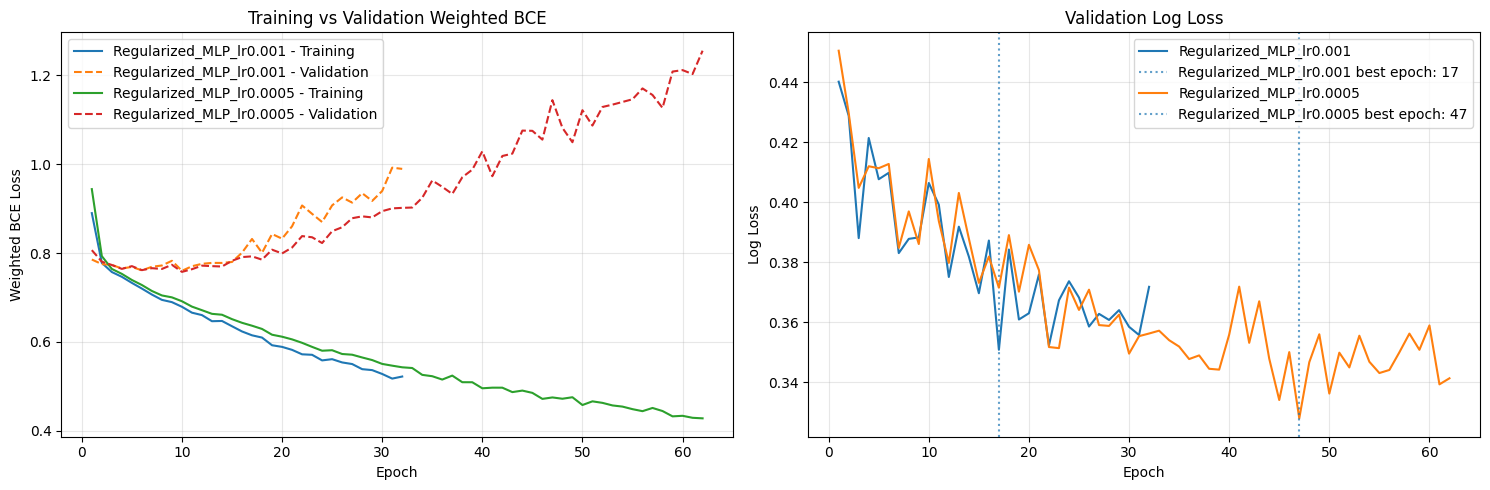

In [197]:
# Plot 1: Training vs Validation Weighted BCE
# Plot 2: Validation Log Loss and Best Epoch

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, history in mlp_histories.items():

    epochs = range(1, len(history["train_loss"]) + 1)

    # Training and validation loss
    axes[0].plot(
        epochs, history["train_loss"],
        label=f"{name} - Training"
    )
    axes[0].plot(
        epochs, history["val_loss"],
        linestyle="--",
        label=f"{name} - Validation"
    )

    # Validation log loss
    axes[1].plot(
        epochs, history["val_logloss"],
        label=name
    )

    best_epoch = history["best_epoch"]

    axes[1].axvline(
        best_epoch,
        linestyle=":",
        alpha=0.7,
        label=f"{name} best epoch: {best_epoch}"
    )

# First plot
axes[0].set_title("Training vs Validation Weighted BCE")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted BCE Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Second plot
axes[1].set_title("Validation Log Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Log Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Smaller mlp architecture with regularization

In [198]:

# Experiment 3: Smaller MLP with regularization

def fit_small_mlp(Xa, ya, Xb, yb, seed=SEED,
                  lr=5e-4, epochs=100, patience=15,
                  dropout=0.3, weight_decay=1e-3):

    torch.manual_seed(seed)
    np.random.seed(seed)

    class SmallMLP(nn.Module):
        def __init__(self, d):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(d, 64),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(64, 32),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Linear(32, 1)
            )

        def forward(self, x):
            return self.net(x).squeeze(1)

    model = SmallMLP(Xa.shape[1]).to(DEVICE)

    opt = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    pos = float((len(ya) - ya.sum()) / max(ya.sum(), 1))

    loss_fn = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            pos, dtype=torch.float32, device=DEVICE
        )
    )

    ds = TensorDataset(
        torch.tensor(Xa, dtype=torch.float32),
        torch.tensor(ya.to_numpy(), dtype=torch.float32)
    )

    loader = DataLoader(ds, batch_size=512, shuffle=True)

    xb = torch.tensor(Xb, dtype=torch.float32, device=DEVICE)
    yb_tensor = torch.tensor(
        yb.to_numpy(), dtype=torch.float32, device=DEVICE
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_logloss": []
    }

    best = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for xx, yy in loader:
            xx, yy = xx.to(DEVICE), yy.to(DEVICE)

            opt.zero_grad()
            loss = loss_fn(model(xx), yy)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            opt.step()
            running_loss += loss.item() * len(xx)

        train_loss = running_loss / len(ds)

        model.eval()
        with torch.no_grad():
            logits_tensor = model(xb)
            val_loss = loss_fn(logits_tensor, yb_tensor).item()
            logits = logits_tensor.cpu().numpy()

        probs = 1 / (1 + np.exp(-np.clip(logits, -30, 30)))

        score = log_loss(
            yb, np.clip(probs, 1e-7, 1-1e-7)
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_logloss"].append(score)

        if score < best - 1e-5:
            best = score
            best_epoch = epoch + 1
            wait = 0
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
        else:
            wait += 1

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(
                f"Epoch {epoch+1:3d} | "
                f"Train Loss: {train_loss:.4f} | "
                f"Val Loss: {val_loss:.4f} | "
                f"Val LogLoss: {score:.4f}"
            )

        if wait >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    history["best_epoch"] = best_epoch

    print(f"Best epoch: {best_epoch}, Best Val LogLoss: {best:.4f}")

    return model, history


# Train Experiment 3
if TORCH_AVAILABLE:
    small_mlp, small_mlp_history = fit_small_mlp(
        Xtr, y_train, Xva, y_val,
        seed=SEED,
        lr=5e-4,
        dropout=0.3,
        weight_decay=1e-3
    )

    small_mlp_probs = mlp_predict(small_mlp, Xva)

    small_mlp_metrics = metric_row(
        "Smaller_MLP_lr0.0005", y_val, small_mlp_probs
    )

    display(pd.DataFrame([small_mlp_metrics]))


Epoch   1 | Train Loss: 0.9700 | Val Loss: 0.8199 | Val LogLoss: 0.4544
Epoch   5 | Train Loss: 0.7453 | Val Loss: 0.7724 | Val LogLoss: 0.4029
Epoch  10 | Train Loss: 0.7044 | Val Loss: 0.7717 | Val LogLoss: 0.3794
Epoch  15 | Train Loss: 0.6702 | Val Loss: 0.7868 | Val LogLoss: 0.3618
Epoch  20 | Train Loss: 0.6416 | Val Loss: 0.8019 | Val LogLoss: 0.3740
Epoch  25 | Train Loss: 0.6118 | Val Loss: 0.8190 | Val LogLoss: 0.3470
Epoch  30 | Train Loss: 0.5954 | Val Loss: 0.8445 | Val LogLoss: 0.3500
Epoch  35 | Train Loss: 0.5745 | Val Loss: 0.8740 | Val LogLoss: 0.3552
Epoch  40 | Train Loss: 0.5555 | Val Loss: 0.8873 | Val LogLoss: 0.3648
Early stopping at epoch 40
Best epoch: 25, Best Val LogLoss: 0.3470


,candidate,ROC_AUC,PR_AUC,Brier,LogLoss
0,Smaller_MLP_lr0.0005,0.888775,0.538621,0.111955,0.346957


learning curves

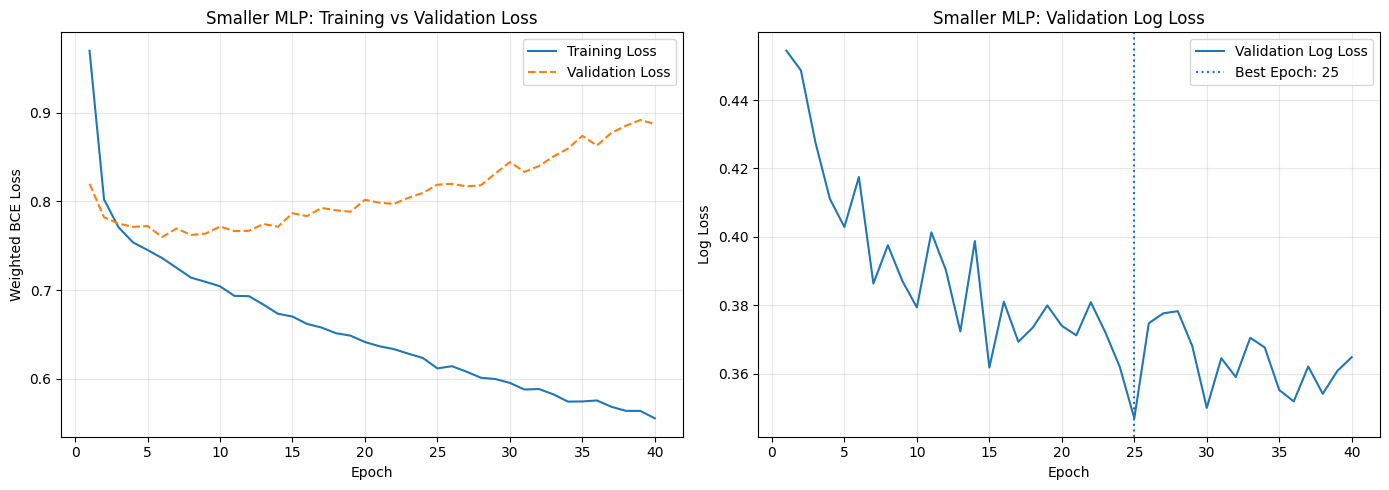

In [199]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, len(small_mlp_history["train_loss"]) + 1)

axes[0].plot(
    epochs, small_mlp_history["train_loss"],
    label="Training Loss"
)
axes[0].plot(
    epochs, small_mlp_history["val_loss"],
    linestyle="--", label="Validation Loss"
)

axes[0].set_title("Smaller MLP: Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted BCE Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs, small_mlp_history["val_logloss"],
    label="Validation Log Loss"
)
axes[1].axvline(
    small_mlp_history["best_epoch"],
    linestyle=":", label=f"Best Epoch: {small_mlp_history['best_epoch']}"
)

axes[1].set_title("Smaller MLP: Validation Log Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Log Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Comparison of MLP Architectures and Regularization Experiments

,Experiment,ROC_AUC,PR_AUC,Brier,LogLoss
0,Baseline MLP,0.881962,0.534854,0.112444,0.348961
1,Regularized MLP,0.875896,0.520224,0.101451,0.327896
2,Smaller MLP,0.888775,0.538621,0.111955,0.346957


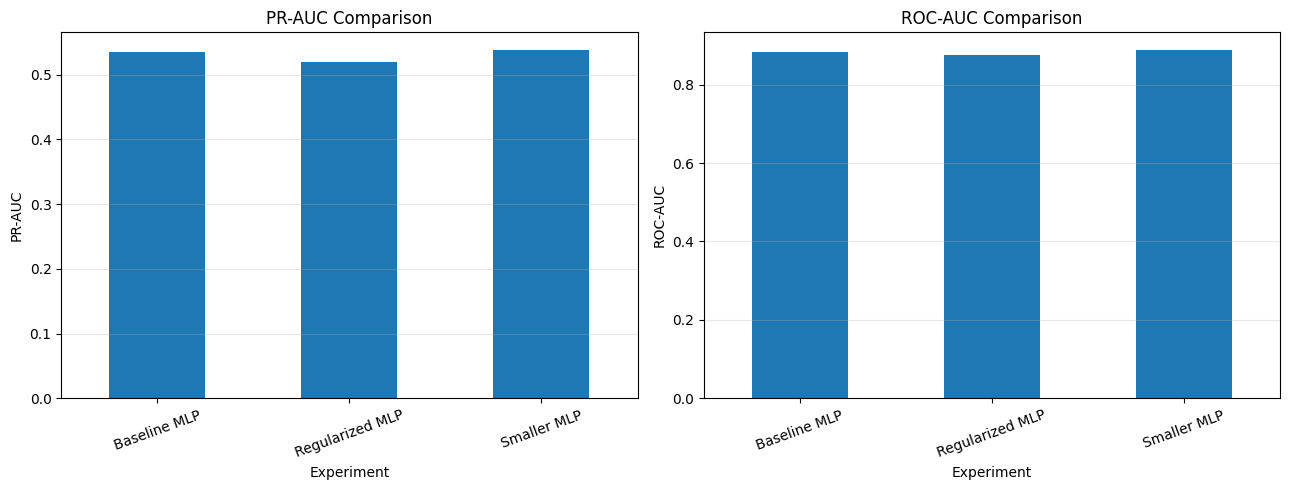

In [200]:

comparison = pd.DataFrame([
    {
        "Experiment": "Baseline MLP",
        "ROC_AUC": 0.881962,
        "PR_AUC": 0.534854,
        "Brier": 0.112444,
        "LogLoss": 0.348961
    },
    {
        "Experiment": "Regularized MLP",
        "ROC_AUC": 0.875896,
        "PR_AUC": 0.520224,
        "Brier": 0.101451,
        "LogLoss": 0.327896
    },
    {
        "Experiment": "Smaller MLP",
        "ROC_AUC": 0.888775,
        "PR_AUC": 0.538621,
        "Brier": 0.111955,
        "LogLoss": 0.346957
    }
])

display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

comparison.plot(
    x="Experiment", y="PR_AUC", kind="bar",
    ax=axes[0], legend=False
)
axes[0].set_title("PR-AUC Comparison")
axes[0].set_ylabel("PR-AUC")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.3)

comparison.plot(
    x="Experiment", y="ROC_AUC", kind="bar",
    ax=axes[1], legend=False
)
axes[1].set_title("ROC-AUC Comparison")
axes[1].set_ylabel("ROC-AUC")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


###MLP Reproducibility Across Random Seeds

In [201]:

# Experiment 4: Reproducibility across random seeds

REPRO_SEEDS = [11, 29, 42, 47]

seed_results = []
seed_models = {}
seed_histories = {}

for seed in REPRO_SEEDS:
    print(f"\nTraining Smaller MLP with seed={seed}")

    model_seed, history_seed = fit_small_mlp(
        Xtr, y_train, Xva, y_val,
        seed=seed,
        lr=5e-4,
        epochs=100,
        patience=15,
        dropout=0.3,
        weight_decay=1e-3
    )

    probs_seed = mlp_predict(model_seed, Xva)

    metrics = metric_row(
        f"Smaller_MLP_seed_{seed}",
        y_val,
        probs_seed
    )

    metrics["Best_Epoch"] = history_seed["best_epoch"]

    seed_results.append(metrics)
    seed_models[seed] = model_seed
    seed_histories[seed] = history_seed

seed_results_df = pd.DataFrame(seed_results)

display(seed_results_df)



Training Smaller MLP with seed=11
Epoch   1 | Train Loss: 0.9668 | Val Loss: 0.8192 | Val LogLoss: 0.4407
Epoch   5 | Train Loss: 0.7464 | Val Loss: 0.7710 | Val LogLoss: 0.4126
Epoch  10 | Train Loss: 0.7049 | Val Loss: 0.7654 | Val LogLoss: 0.4001
Epoch  15 | Train Loss: 0.6708 | Val Loss: 0.7757 | Val LogLoss: 0.3792
Epoch  20 | Train Loss: 0.6407 | Val Loss: 0.7917 | Val LogLoss: 0.3640
Epoch  25 | Train Loss: 0.6160 | Val Loss: 0.8078 | Val LogLoss: 0.3635
Epoch  30 | Train Loss: 0.5899 | Val Loss: 0.8495 | Val LogLoss: 0.3491
Epoch  35 | Train Loss: 0.5691 | Val Loss: 0.8585 | Val LogLoss: 0.3685
Epoch  40 | Train Loss: 0.5522 | Val Loss: 0.8735 | Val LogLoss: 0.3645
Epoch  45 | Train Loss: 0.5368 | Val Loss: 0.9084 | Val LogLoss: 0.3567
Epoch  50 | Train Loss: 0.5231 | Val Loss: 0.9324 | Val LogLoss: 0.3608
Epoch  55 | Train Loss: 0.5051 | Val Loss: 0.9676 | Val LogLoss: 0.3708
Epoch  60 | Train Loss: 0.4990 | Val Loss: 1.0247 | Val LogLoss: 0.3497
Epoch  65 | Train Loss: 0.479

,candidate,ROC_AUC,PR_AUC,Brier,LogLoss,Best_Epoch
0,Smaller_MLP_seed_11,0.882882,0.526397,0.105876,0.328900,53
1,Smaller_MLP_seed_29,0.879251,0.523716,0.110461,0.342274,49
2,Smaller_MLP_seed_42,0.888775,0.538621,0.111955,0.346957,25
3,Smaller_MLP_seed_47,0.879697,0.526749,0.113379,0.349611,40


### Reproducibility Summary

In [202]:

# Calculate mean and standard deviation across seeds

repro_summary = seed_results_df[
    ["ROC_AUC", "PR_AUC", "Brier", "LogLoss", "Best_Epoch"]
].agg(["mean", "std"])

display(repro_summary)


,ROC_AUC,PR_AUC,Brier,LogLoss,Best_Epoch
mean,0.882651,0.528871,0.110418,0.341936,41.750000
std,0.004391,0.006640,0.003254,0.009205,12.419742


### Performance Variation Across Random Seeds

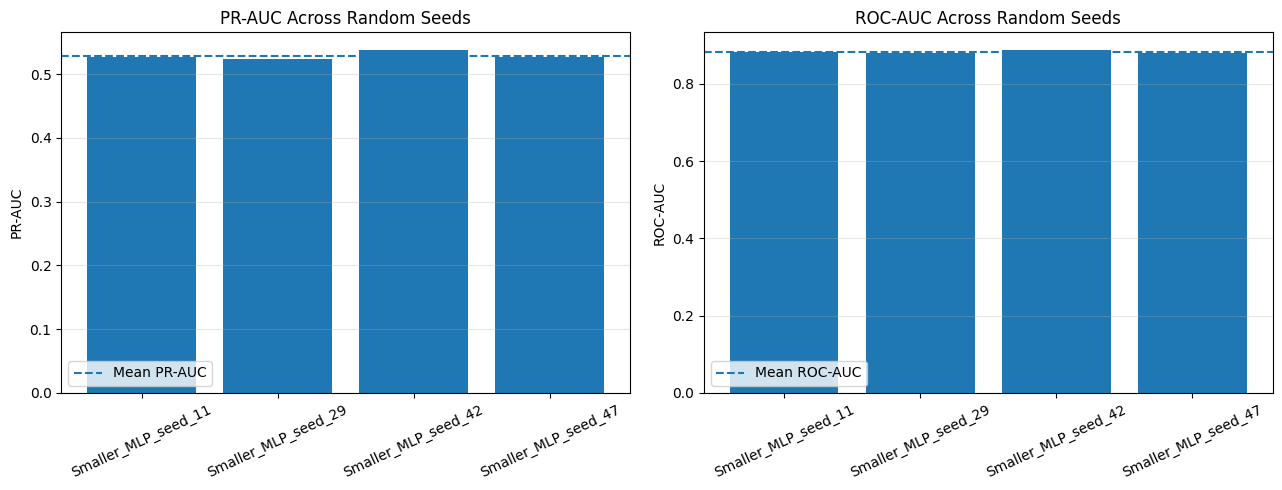

In [203]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    seed_results_df["candidate"],
    seed_results_df["PR_AUC"]
)
axes[0].axhline(
    seed_results_df["PR_AUC"].mean(),
    linestyle="--",
    label="Mean PR-AUC"
)
axes[0].set_title("PR-AUC Across Random Seeds")
axes[0].set_ylabel("PR-AUC")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    seed_results_df["candidate"],
    seed_results_df["ROC_AUC"]
)
axes[1].axhline(
    seed_results_df["ROC_AUC"].mean(),
    linestyle="--",
    label="Mean ROC-AUC"
)
axes[1].set_title("ROC-AUC Across Random Seeds")
axes[1].set_ylabel("ROC-AUC")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## 6. Validation-only model selection and threshold locking
Select by validation PR-AUC (ROC-AUC tie-breaker). Select the F1 operating threshold on validation only.

In [ ]:

# 7. Validation-only model selection and threshold locking

# Add the Smaller MLP to the validation comparison
all_validation_results = pd.concat(
    [
        validation_results,
        pd.DataFrame([small_mlp_metrics])
    ],
    ignore_index=True
)

# Select model using PR-AUC, ROC-AUC as tie-breaker
all_validation_results = all_validation_results.sort_values(
    ["PR_AUC", "ROC_AUC"],
    ascending=False
).reset_index(drop=True)

display(all_validation_results)

selected_name = all_validation_results.iloc[0]["candidate"]

# Retrieve the selected model and its validation probabilities
if selected_name == "Smaller_MLP_lr0.0005":
    selected_model = small_mlp
    selected_val_prob = small_mlp_probs
else:
    selected_model = models[selected_name]
    selected_val_prob = val_probs[selected_name]

# Select F1-maximizing threshold using validation data only
precision, recall, thresholds = precision_recall_curve(
    y_val, selected_val_prob
)

f1_vals = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_threshold_idx = int(np.nanargmax(f1_vals))
LOCKED_THRESHOLD = float(thresholds[best_threshold_idx])

print("Frozen model:", selected_name)
print("Validation PR-AUC:",
      float(all_validation_results.iloc[0]["PR_AUC"]))
print("Validation ROC-AUC:",
      float(all_validation_results.iloc[0]["ROC_AUC"]))
print("Validation F1:", float(f1_vals[best_threshold_idx]))
print("Locked threshold:", LOCKED_THRESHOLD)


,candidate,ROC_AUC,PR_AUC,Brier,LogLoss
0,Smaller_MLP_lr0.0005,0.888775,0.538621,0.111955,0.346957
1,Regularized_MLP_lr0.001,0.885847,0.530002,0.116025,0.350778
2,Regularized_MLP_lr0.0005,0.875896,0.520224,0.101451,0.327896
3,RandomForest_leaf5,0.885724,0.516878,0.063120,0.227136
4,RandomForest_leaf15,0.886250,0.516160,0.085153,0.292070
5,LogisticRegression_C0.1,0.885245,0.498671,0.133811,0.428577
6,LogisticRegression_C1.0,0.884953,0.497824,0.133906,0.428791


Frozen model: Smaller_MLP_lr0.0005
Validation PR-AUC: 0.5386205562850783
Validation ROC-AUC: 0.8887747713429949
Validation F1: 0.5017978425883947
Locked threshold: 0.7909806966781616


## 7. One-time locked test evaluation
This is the only primary test evaluation. Do not use the result to change the model, threshold or counterfactual settings.

In [ ]:
from sklearn.metrics import precision_score, recall_score

In [ ]:

# 8. One-time locked test evaluation

def predict_model(m, name, arr):
    if isinstance(m, nn.Module):
        return mlp_predict(m, arr)
    return m.predict_proba(arr)[:, 1]


# Generate test probabilities exactly once
test_prob = np.clip(
    predict_model(selected_model, selected_name, Xte),
    1e-7, 1-1e-7
)

# Apply the threshold selected on validation data
test_pred = (test_prob >= LOCKED_THRESHOLD).astype(int)

# Calculate test metrics
locked_test = metric_row(selected_name, y_test, test_prob)

cm = confusion_matrix(y_test, test_pred, labels=[0, 1])

locked_test.update({
    "threshold": LOCKED_THRESHOLD,
    "F1": f1_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall": recall_score(y_test, test_pred, zero_division=0),
    "sensitivity": cm[1, 1] / max(1, cm[1].sum()),
    "specificity": cm[0, 0] / max(1, cm[0].sum())
})

display(pd.DataFrame([locked_test]))

print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)


,candidate,ROC_AUC,PR_AUC,Brier,LogLoss,threshold,F1,precision,recall,sensitivity,specificity
0,Smaller_MLP_lr0.0005,0.899705,0.581038,0.107035,0.330795,0.790981,0.533225,0.513661,0.554339,0.554339,0.950438


Confusion matrix [[TN, FP], [FN, TP]]:
 [[11947   623]
 [  529   658]]


## 8. Test-set model-family comparison and paired bootstrap
Refit the best validation candidate within each family using its fixed configuration. These test metrics are descriptive comparisons only; they cannot change the selected model. Paired bootstrap resamples the same test rows for each model pair.

In [ ]:

print("Validation candidate names:")
print(validation_results["candidate"].tolist())

print("\nAll validation candidate names:")
print(all_validation_results["candidate"].tolist())

print("\nProbability array shapes:")
print("small_mlp_probs:", np.asarray(small_mlp_probs).shape)
print("y_val:", np.asarray(y_val).shape)
print("y_test:", np.asarray(y_test).shape)
print("Xte:", Xte.shape)

print("\nSelected model:")
print(selected_name)


Validation candidate names:
['Regularized_MLP_lr0.001', 'Regularized_MLP_lr0.0005', 'RandomForest_leaf5', 'RandomForest_leaf15', 'LogisticRegression_C0.1', 'LogisticRegression_C1.0']

All validation candidate names:
['Smaller_MLP_lr0.0005', 'Regularized_MLP_lr0.001', 'Regularized_MLP_lr0.0005', 'RandomForest_leaf5', 'RandomForest_leaf15', 'LogisticRegression_C0.1', 'LogisticRegression_C1.0']

Probability array shapes:
small_mlp_probs: (13757,)
y_val: (13757,)
y_test: (13757,)
Xte: (13757, 397)

Selected model:
Smaller_MLP_lr0.0005


Selected validation configurations:
{'LogisticRegression': 'LogisticRegression_C0.1', 'RandomForest': 'RandomForest_leaf5', 'MLP': 'Smaller_MLP_lr0.0005'}


,candidate,ROC_AUC,PR_AUC,Brier,LogLoss
2,MLP,0.899705,0.581038,0.107035,0.330795
0,LogisticRegression,0.897640,0.548131,0.129760,0.413237
1,RandomForest,0.895179,0.537107,0.061196,0.222372


,model_family,PR_AUC_median,PR_AUC_CI_2.5%,PR_AUC_CI_97.5%
0,LogisticRegression,0.548597,0.519554,0.575933
1,RandomForest,0.536970,0.508785,0.565006
2,MLP,0.580601,0.553033,0.607458


,comparison,delta_PR_AUC_median,CI_2.5%,CI_97.5%
0,LogisticRegression - RandomForest,0.011685,-0.006034,0.028155
1,LogisticRegression - MLP,-0.032789,-0.049107,-0.017042
2,RandomForest - MLP,-0.044197,-0.060746,-0.027645


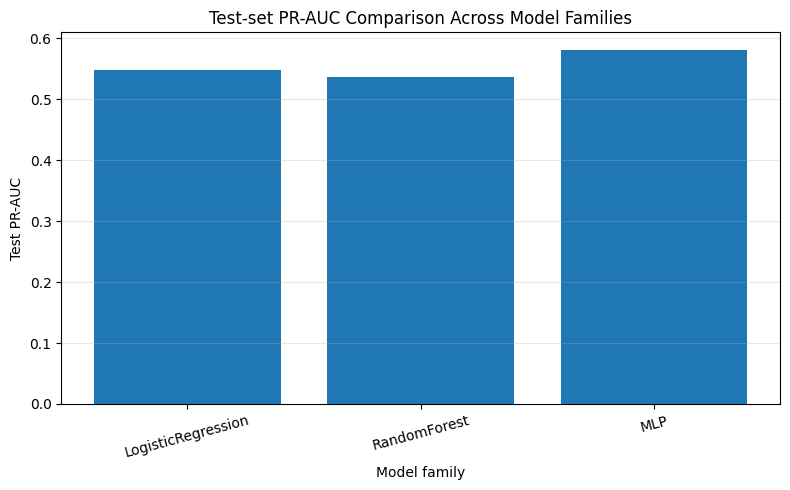

In [ ]:

# 9. Test-set model-family comparison and paired bootstrap
# Descriptive comparison only. Does not change the selected model.

# --------------------------------------------------
# 1. Select best validation configuration per family
# --------------------------------------------------

family_best = {}

lr_results = validation_results[
    validation_results["candidate"].str.startswith("LogisticRegression_")
].sort_values("PR_AUC", ascending=False)

rf_results = validation_results[
    validation_results["candidate"].str.startswith("RandomForest_")
].sort_values("PR_AUC", ascending=False)

if len(lr_results):
    family_best["LogisticRegression"] = lr_results.iloc[0]["candidate"]

if len(rf_results):
    family_best["RandomForest"] = rf_results.iloc[0]["candidate"]

# Our already-selected final Smaller MLP
family_best["MLP"] = selected_name

print("Selected validation configurations:")
print(family_best)


# --------------------------------------------------
# 2. Generate test probabilities for each family
# --------------------------------------------------

family_test_probs = {}

# Logistic Regression
name = family_best["LogisticRegression"]
c = float(name.split("_C")[1])

lr_model = LogisticRegression(
    C=c,
    max_iter=1500,
    class_weight="balanced"
)
lr_model.fit(Xtr, y_train)

family_test_probs["LogisticRegression"] = (
    lr_model.predict_proba(Xte)[:, 1]
)


# Random Forest
name = family_best["RandomForest"]
leaf = int(name.split("leaf")[1])

rf_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=leaf,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=SEED
)
rf_model.fit(Xtr, y_train)

family_test_probs["RandomForest"] = (
    rf_model.predict_proba(Xte)[:, 1]
)


# Final selected Smaller MLP
# Use test inputs, NOT the validation probability array
family_test_probs["MLP"] = mlp_predict(small_mlp, Xte)


# --------------------------------------------------
# 3. Test-set model-family metrics
# --------------------------------------------------

family_metrics = pd.DataFrame([
    metric_row(family, y_test, prob)
    for family, prob in family_test_probs.items()
])

display(
    family_metrics.sort_values("PR_AUC", ascending=False)
)


# --------------------------------------------------
# 4. Bootstrap confidence intervals for PR-AUC
# --------------------------------------------------

def bootstrap_metric_ci(
    y_true, prob, reps=BOOTSTRAP_REPS, seed=SEED
):
    rng = np.random.default_rng(seed)

    yy = np.asarray(y_true)
    pp = np.asarray(prob)

    vals = []

    for _ in range(reps):
        ix = rng.integers(0, len(yy), len(yy))

        if len(np.unique(yy[ix])) < 2:
            continue

        vals.append(
            average_precision_score(yy[ix], pp[ix])
        )

    return np.quantile(vals, [0.025, 0.5, 0.975])


family_ci_rows = []

for fam, prob in family_test_probs.items():
    lo, med, hi = bootstrap_metric_ci(y_test, prob)

    family_ci_rows.append({
        "model_family": fam,
        "PR_AUC_median": med,
        "PR_AUC_CI_2.5%": lo,
        "PR_AUC_CI_97.5%": hi
    })

family_pr_auc_ci = pd.DataFrame(family_ci_rows)
display(family_pr_auc_ci)


# --------------------------------------------------
# 5. Paired bootstrap comparison of PR-AUC
# --------------------------------------------------

def paired_bootstrap_delta(
    y_true, a, b, reps=BOOTSTRAP_REPS, seed=SEED
):
    rng = np.random.default_rng(seed)

    y0 = np.asarray(y_true)
    a = np.asarray(a)
    b = np.asarray(b)

    diffs = []

    for _ in range(reps):
        ix = rng.integers(0, len(y0), len(y0))

        if len(np.unique(y0[ix])) < 2:
            continue

        delta = (
            average_precision_score(y0[ix], a[ix])
            - average_precision_score(y0[ix], b[ix])
        )

        diffs.append(delta)

    return np.quantile(diffs, [0.025, 0.5, 0.975])


rows = []
families = list(family_test_probs)

for i in range(len(families)):
    for j in range(i + 1, len(families)):
        a, b = families[i], families[j]

        lo, med, hi = paired_bootstrap_delta(
            y_test,
            family_test_probs[a],
            family_test_probs[b]
        )

        rows.append({
            "comparison": f"{a} - {b}",
            "delta_PR_AUC_median": med,
            "CI_2.5%": lo,
            "CI_97.5%": hi
        })

paired_model_bootstrap = pd.DataFrame(rows)
display(paired_model_bootstrap)


# --------------------------------------------------
# 6. Visual comparison of test PR-AUC
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    family_metrics["candidate"],
    family_metrics["PR_AUC"]
)

plt.ylabel("Test PR-AUC")
plt.xlabel("Model family")
plt.title("Test-set PR-AUC Comparison Across Model Families")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Training and Model Evaluation Visualizations

This section presents visual comparisons of model learning behaviour and predictive performance. Training and validation loss curves are used to examine learning and generalization, while comparative evaluation plots assess performance across Logistic Regression, Random Forest, and MLP.

#### 9.1 MLP Training and Validation Loss vs Epochs

This plot shows the MLP's training and validation loss over successive epochs. It helps identify convergence and potential overfitting by comparing performance on training and validation data. The best epoch selected during training is also highlighted.

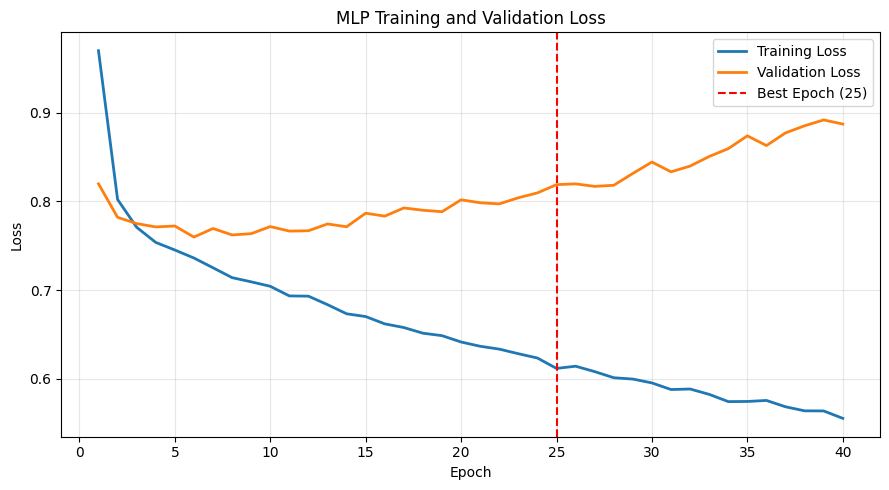

In [184]:
epochs = range(1, len(small_mlp_history["train_loss"]) + 1)

best_epoch = small_mlp_history["best_epoch"]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    epochs,
    small_mlp_history["train_loss"],
    label="Training Loss",
    linewidth=2
)

ax.plot(
    epochs,
    small_mlp_history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

ax.axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("MLP Training and Validation Loss")
ax.set_xticks(range(0, 41, 5))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 9.2 Model Performance Comparison

This visualization compares Logistic Regression, Random Forest, and MLP using standard classification metrics. It helps identify differences in predictive performance across the three models.

In [187]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score
)

performance_rows = []

for model_name, probabilities in model_probabilities.items():
    for split, y_true in [
        ("train", y_train),
        ("test", y_test)
    ]:
        probs = np.asarray(probabilities[split]).ravel()
        predictions = (probs >= 0.5).astype(int)

        performance_rows.append({
            "Model": model_name,
            "Dataset": split.capitalize(),
            "Accuracy": accuracy_score(y_true, predictions),
            "Precision": precision_score(y_true, predictions, zero_division=0),
            "Recall": recall_score(y_true, predictions, zero_division=0),
            "F1-score": f1_score(y_true, predictions, zero_division=0),
            "PR-AUC": average_precision_score(y_true, probs)
        })

performance_df = pd.DataFrame(performance_rows)

display(performance_df.round(4))

,Model,Dataset,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Logistic Regression,Train,0.8207,0.2992,0.8032,0.4360,0.5182
1,Logistic Regression,Test,0.8191,0.2963,0.7970,0.4320,0.5481
2,Random Forest,Train,0.9921,0.9229,0.9917,0.9561,0.9846
3,Random Forest,Test,0.9267,0.6271,0.3698,0.4653,0.5371
4,MLP,Train,0.8643,0.3789,0.8949,0.5324,0.6718
5,MLP,Test,0.8416,0.3239,0.7683,0.4557,0.5810


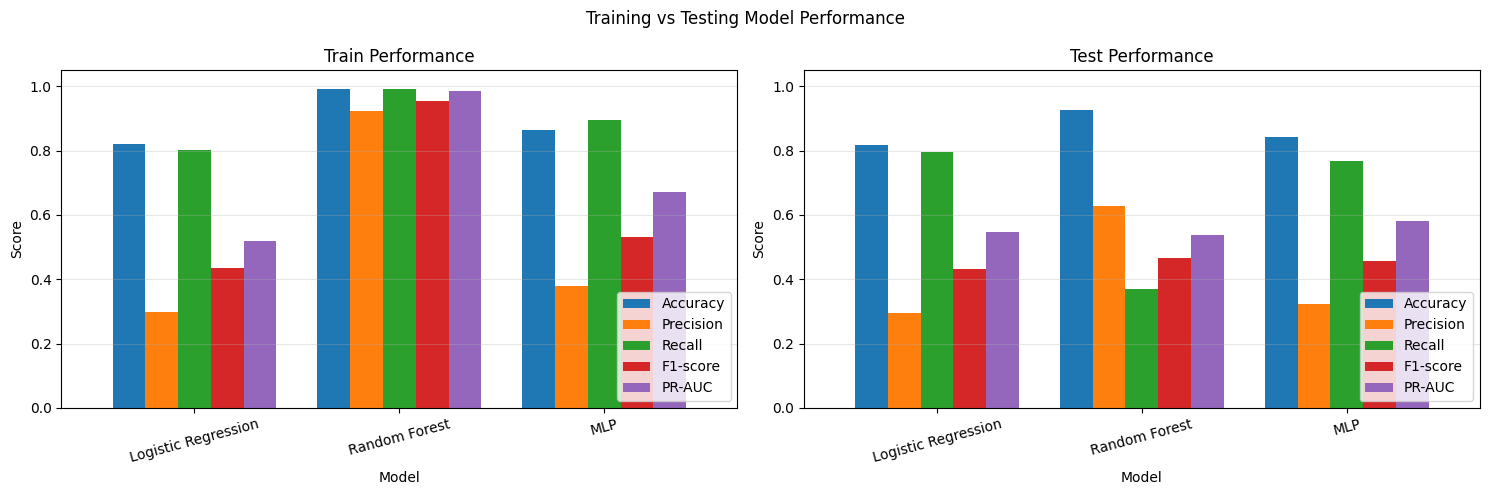

In [190]:
metrics_to_plot = [
    "Accuracy", "Precision", "Recall", "F1-score", "PR-AUC"
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, dataset in zip(axes, ["Train", "Test"]):
    subset = performance_df[
        performance_df["Dataset"] == dataset
    ].set_index("Model")

    subset[metrics_to_plot].plot(
        kind="bar",
        ax=ax,
        width=0.8
    )

    ax.set_title(f"{dataset} Performance")
    ax.set_ylabel("Score")
    ax.set_xlabel("Model")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=15)
    ax.legend(loc="lower right")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Training vs Testing Model Performance")
plt.tight_layout()
plt.show()

## 10. Mutable features, bounds and cross-feature constraints
Numeric features with adequate support are eligible, except demographic/immutable variables. Bounds are training 1st–99th percentiles. Exact matching `_min`/`_max` pairs are discovered from the actual table.

In [ ]:
mutable = []
bounds = {}
for c in num_cols:
    s = pd.to_numeric(X_train[c], errors="coerce").dropna()
    if len(s)>=100 and s.nunique()>=10:
        bounds[c]=(float(s.quantile(.01)),float(s.quantile(.99)))
        mutable.append(c)
IMMUTABLE_TOKENS=("age","gender","ethnicity","race","height","weight","bmi")
mutable=[c for c in mutable if not any(t in c.lower() for t in IMMUTABLE_TOKENS)]
pairs=[]
for c in X.columns:
    if c.endswith("_min") and c[:-4]+"_max" in X.columns:
        pairs.append((c,c[:-4]+"_max"))
print("Mutable features:",len(mutable))
print("Detected min/max pairs:",pairs)

Mutable features: 149
Detected min/max pairs: [('d1_diasbp_invasive_min', 'd1_diasbp_invasive_max'), ('d1_diasbp_min', 'd1_diasbp_max'), ('d1_diasbp_noninvasive_min', 'd1_diasbp_noninvasive_max'), ('d1_heartrate_min', 'd1_heartrate_max'), ('d1_mbp_invasive_min', 'd1_mbp_invasive_max'), ('d1_mbp_min', 'd1_mbp_max'), ('d1_mbp_noninvasive_min', 'd1_mbp_noninvasive_max'), ('d1_resprate_min', 'd1_resprate_max'), ('d1_spo2_min', 'd1_spo2_max'), ('d1_sysbp_invasive_min', 'd1_sysbp_invasive_max'), ('d1_sysbp_min', 'd1_sysbp_max'), ('d1_sysbp_noninvasive_min', 'd1_sysbp_noninvasive_max'), ('d1_temp_min', 'd1_temp_max'), ('h1_diasbp_invasive_min', 'h1_diasbp_invasive_max'), ('h1_diasbp_min', 'h1_diasbp_max'), ('h1_diasbp_noninvasive_min', 'h1_diasbp_noninvasive_max'), ('h1_heartrate_min', 'h1_heartrate_max'), ('h1_mbp_invasive_min', 'h1_mbp_invasive_max'), ('h1_mbp_min', 'h1_mbp_max'), ('h1_mbp_noninvasive_min', 'h1_mbp_noninvasive_max'), ('h1_resprate_min', 'h1_resprate_max'), ('h1_spo2_min', '

In [ ]:
print("Number of mutable features:", len(mutable))

print("\nMutable feature names:")
for c in mutable:
    print(c, ":", bounds[c])

print("\nDetected min/max pairs:")
print(pairs)

Number of mutable features: 149

Mutable feature names:
pre_icu_los_days : (0.0, 10.86116666559999)
albumin_apache : (1.3, 4.4)
apache_2_diagnosis : (102.0, 308.0)
apache_3j_diagnosis : (102.01, 1902.01)
bilirubin_apache : (0.2, 9.9)
bun_apache : (4.0, 108.0)
creatinine_apache : (0.37, 9.059700000000012)
fio2_apache : (0.21, 1.0)
glucose_apache : (49.0, 502.0)
heart_rate_apache : (34.0, 168.0)
hematocrit_apache : (17.8, 49.3)
map_apache : (40.0, 193.0)
paco2_apache : (20.0, 87.8)
paco2_for_ph_apache : (20.0, 87.8)
pao2_apache : (39.407999999999994, 462.0)
ph_apache : (7.03608, 7.56)
resprate_apache : (4.0, 60.0)
sodium_apache : (121.0, 153.0)
temp_apache : (32.8, 39.3)
urineoutput_apache : (0.0, 7228.759680000002)
wbc_apache : (1.88, 38.4)
d1_diasbp_invasive_max : (42.0, 165.0)
d1_diasbp_invasive_min : (10.0, 82.0)
d1_diasbp_max : (51.0, 151.0)
d1_diasbp_min : (17.0, 84.0)
d1_diasbp_noninvasive_max : (51.0, 151.0)
d1_diasbp_noninvasive_min : (17.0, 85.0)
d1_heartrate_max : (60.0, 166.0

In [ ]:

# Refine mutable features: exclude diagnosis codes and historical duration

NON_ACTIONABLE = {
    "apache_2_diagnosis",
    "apache_3j_diagnosis",
    "pre_icu_los_days"
}

mutable = [
    c for c in mutable
    if c not in NON_ACTIONABLE
]

for c in NON_ACTIONABLE:
    bounds.pop(c, None)

print("Refined mutable feature count:", len(mutable))
print("Excluded non-actionable features:", NON_ACTIONABLE)


Refined mutable feature count: 146
Excluded non-actionable features: {'apache_3j_diagnosis', 'pre_icu_los_days', 'apache_2_diagnosis'}


## 11. Counterfactual Search Methods

This section implements constrained counterfactual search to identify small changes in eligible patient features that can move the selected MLP's predicted mortality risk below the locked decision threshold.

We follow the original project methodology:

1. **Gradient-guided search (MLP):** Uses PyTorch autograd and backpropagation to calculate the sensitivity of the MLP's predicted risk to its input features. These gradients guide feature selection and the direction of modification.
2. **Random-feature search:** Selects eligible features randomly and searches for changes that reduce predicted risk.
3. **Greedy single-feature search:** Evaluates individual feature modifications and selects the change that produces the greatest immediate reduction in predicted risk.

All methods use the same frozen model, decision threshold, eligible feature set, training-derived feature bounds, feature-change budget, and evaluation budget.

Additional constraints preserve immutable features, prevent invalid min/max relationships, and restrict candidate values to predefined ranges. Counterfactuals are evaluated based on prediction-flip success, sparsity, proximity, feasibility, and stability.

These counterfactuals explain model behaviour and are not medical treatment recommendations or evidence of causal effects.

**Autograd verification:** Before running the complete search, we verify that gradients can be calculated successfully for all eligible mutable features.

In [ ]:
import torch
import numpy as np
import pandas as pd

# Use the frozen, selected MLP and threshold.
CF_MODEL = small_mlp
CF_MODEL.eval()

# Map original numeric feature names to their transformed numeric columns.
feature_names = list(preprocessor.get_feature_names_out())

feature_to_idx = {}
for f in mutable:
    matches = [
        i for i, name in enumerate(feature_names)
        if name.endswith("__" + f) or name == f
    ]
    if len(matches) == 1:
        feature_to_idx[f] = matches[0]

print("Mutable features mapped to transformed columns:", len(feature_to_idx))
print("Unmapped features:", len(mutable) - len(feature_to_idx))


def transform_row(row):
    z = preprocessor.transform(
        pd.DataFrame([row], columns=X_train.columns)
    )
    if hasattr(z, "toarray"):
        z = z.toarray()
    return np.asarray(z, dtype=np.float32)


def predict_raw(row, model=None):
    model = CF_MODEL if model is None else model
    z = transform_row(row)
    if model is CF_MODEL:
        return float(mlp_predict(model, z)[0])
    return float(predict_model(model, selected_name, z)[0])


def mlp_input_gradients(row):
    """Autograd gradients of the MLP logit w.r.t. transformed inputs."""
    z = torch.tensor(transform_row(row), dtype=torch.float32,
                     requires_grad=True)

    CF_MODEL.eval()
    output = CF_MODEL(z)

    # Differentiate the model output with respect to its input.
    if output.ndim > 1 and output.shape[-1] == 1:
        output = output.reshape(-1)

    logit = output.sum()
    gradients = torch.autograd.grad(logit, z)[0]

    return gradients.detach().cpu().numpy().ravel()


def project_pairs(row, changed=None):
    out = row.copy()

    for lo_col, hi_col in pairs:
        lo, hi = out.get(lo_col, np.nan), out.get(hi_col, np.nan)

        if pd.isna(lo) or pd.isna(hi) or float(lo) <= float(hi):
            continue

        if changed == lo_col:
            out[lo_col] = hi
        elif changed == hi_col:
            out[hi_col] = lo
        else:
            mid = (float(lo) + float(hi)) / 2
            out[lo_col], out[hi_col] = mid, mid

    return out


def candidate(row, feature, value):
    out = row.copy()
    out[feature] = value
    out = project_pairs(out, feature)

    for f in mutable:
        if f in out.index and f in bounds and pd.notna(out[f]):
            lo, hi = bounds[f]
            if float(out[f]) < lo - 1e-8 or float(out[f]) > hi + 1e-8:
                return None, None

    return out, predict_raw(out)


def change_cost(a, b):
    total = 0.0
    for f in mutable:
        if pd.notna(a[f]) and pd.notna(b[f]):
            lo, hi = bounds[f]
            total += abs(float(b[f]) - float(a[f])) / max(hi - lo, 1e-8)
    return float(total)


def search_cf_mlp(original, rng):
    target = LOCKED_THRESHOLD - CF_TARGET_MARGIN
    initial = predict_raw(original)

    current = original.copy()
    changed = set()
    evaluations = 1

    if initial <= target:
        return {
            "success": True, "already_below": True,
            "row": current, "p0": initial, "p_final": initial,
            "changed": [], "cost": 0.0, "evaluations": evaluations
        }

    for step in range(CF_MAX_STEPS):
        remaining = [
            f for f in mutable
            if f not in changed
            and f in feature_to_idx
            and pd.notna(current[f])
        ]

        if (not remaining
            or len(changed) >= CF_MAX_FEATURES
            or evaluations >= CF_EVAL_BUDGET):
            break

        # Genuine autograd sensitivity of the MLP.
        gradients = mlp_input_gradients(current)

        # For a lower-risk counterfactual, prefer features whose
        # positive-direction change has a negative risk gradient,
        # or whose negative-direction change has a positive gradient.
        ranked = []
        for f in remaining:
            idx = feature_to_idx[f]
            grad = float(gradients[idx])
            lo, hi = bounds[f]
            span = max(hi - lo, 1e-8)

            # Sensitivity scaled by the feature's allowed range.
            ranked.append((abs(grad) * span, f, grad))

        ranked.sort(reverse=True)

        chosen_feature = None
        chosen_candidate = None
        chosen_probability = predict_raw(current)

        # Try the most sensitive feature first, following the
        # direction that decreases the MLP output.
        for _, f, grad in ranked:
            lo, hi = bounds[f]
            cur = float(current[f])

            if grad > 0:
                trial_values = np.linspace(cur, lo, 13)[1:]
            elif grad < 0:
                trial_values = np.linspace(cur, hi, 13)[1:]
            else:
                continue

            best_local = None

            for value in trial_values:
                cand, prob = candidate(current, f, float(value))
                evaluations += 1

                if cand is not None and prob < chosen_probability:
                    if best_local is None or prob < best_local[0]:
                        best_local = (prob, cand)

                if evaluations >= CF_EVAL_BUDGET:
                    break

            if best_local is not None:
                chosen_feature = f
                chosen_probability, chosen_candidate = best_local
                break

            if evaluations >= CF_EVAL_BUDGET:
                break

        if chosen_candidate is None:
            break

        current = chosen_candidate
        changed.add(chosen_feature)

        if predict_raw(current) <= target:
            break

    final = predict_raw(current)

    return {
        "success": bool(final <= target),
        "already_below": False,
        "row": current,
        "p0": initial,
        "p_final": final,
        "changed": sorted(changed),
        "cost": change_cost(original, current),
        "evaluations": evaluations
    }

Mutable features mapped to transformed columns: 146
Unmapped features: 0


### 11.1 Feature Mapping and Gradient Verification

We verify that eligible mutable features map correctly to the MLP input and that autograd produces valid gradients without NaN or Inf values.


In [ ]:
print("Eligible features:", len(mutable))
print("Mapped features:", len(feature_to_idx))

unmapped = [f for f in mutable if f not in feature_to_idx]
print("Unmapped features:", unmapped)

assert len(unmapped) == 0
assert len(set(feature_to_idx.values())) == len(feature_to_idx)

print("Feature mapping verification passed.")

Eligible features: 146
Mapped features: 146
Unmapped features: []
Feature mapping verification passed.


Gradient verification

In [ ]:
test_gradients = mlp_input_gradients(original_row)

print("Gradient shape:", test_gradients.shape)
print("Expected shape:", len(feature_names))
print("Contains NaN:", np.isnan(test_gradients).any())
print("Contains Inf:", np.isinf(test_gradients).any())

assert len(test_gradients) == len(feature_names)
assert np.isfinite(test_gradients).all()

print("Gradient verification passed.")

Gradient shape: (397,)
Expected shape: 397
Contains NaN: False
Contains Inf: False
Gradient verification passed.


Feature bounds and missing-value audit.

In [ ]:
constraint_audit = []

for f in mutable:
    values = X_train[f].dropna()
    if len(values) == 0:
        continue

    lo, hi = bounds[f]
    value = original_row[f]

    constraint_audit.append({
        "Feature": f,
        "Lower_Bound": lo,
        "Upper_Bound": hi,
        "Original_Value": value,
        "Missing": pd.isna(value),
        "Within_Bounds": (
            pd.isna(value) or lo <= value <= hi
        )
    })

constraint_audit_df = pd.DataFrame(constraint_audit)

print("Eligible features:", len(constraint_audit_df))
print("Missing features:", constraint_audit_df["Missing"].sum())
print("Outside bounds:",
      (~constraint_audit_df["Within_Bounds"]).sum())

display(constraint_audit_df.head(15))

Eligible features: 146
Missing features: 66
Outside bounds: 0


,Feature,Lower_Bound,Upper_Bound,Original_Value,Missing,Within_Bounds
0,albumin_apache,1.30000,4.4000,NaN,True,True
1,bilirubin_apache,0.20000,9.9000,NaN,True,True
2,bun_apache,4.00000,108.0000,34.00,False,True
3,creatinine_apache,0.37000,9.0597,1.36,False,True
4,fio2_apache,0.21000,1.0000,1.00,False,True
5,glucose_apache,49.00000,502.0000,242.00,False,True
6,heart_rate_apache,34.00000,168.0000,124.00,False,True
7,hematocrit_apache,17.80000,49.3000,NaN,True,True
8,map_apache,40.00000,193.0000,45.00,False,True
9,paco2_apache,20.00000,87.8000,29.00,False,True


Min/max constraint audit

In [ ]:
pair_violations = []

for fmin, fmax in pairs:
    if pd.notna(original_row[fmin]) and pd.notna(original_row[fmax]):
        if original_row[fmin] > original_row[fmax]:
            pair_violations.append({
                "Min_Feature": fmin,
                "Max_Feature": fmax,
                "Min_Value": original_row[fmin],
                "Max_Value": original_row[fmax]
            })

print("Total min/max pairs:", len(pairs))
print("Observed violations:", len(pair_violations))

if pair_violations:
    display(pd.DataFrame(pair_violations))
else:
    print("All observed min/max pairs are valid.")

Total min/max pairs: 64
Observed violations: 0
All observed min/max pairs are valid.


###**Target Probability**

In [204]:
CF_TARGET_PROB = LOCKED_THRESHOLD - CF_TARGET_MARGIN

print("Locked threshold:", LOCKED_THRESHOLD)
print("Target probability:", CF_TARGET_PROB)


Locked threshold: 0.7909806966781616
Target probability: 0.7709806966781616


## 12. Preselect held-out test cases
The sample is chosen before running counterfactual methods and is stratified by predicted-risk quantile. The test labels are retained only for descriptive subgroup reporting and are not passed to the search.

In [ ]:
eligible=pd.DataFrame({"position":np.arange(len(X_test)),"index":X_test.index,
                       "y":y_test.to_numpy(),"p":test_prob})
eligible=eligible[eligible.p>(LOCKED_THRESHOLD-CF_TARGET_MARGIN)].copy()
if eligible.empty: raise RuntimeError("No test cases above the counterfactual target.")
eligible["risk_bin"]=pd.qcut(eligible.p.rank(method="first"),q=min(5,eligible.p.nunique()),
                             labels=False,duplicates="drop")
n=min(N_CF_CASES,len(eligible))
sample_parts=[]
for _,g in eligible.groupby("risk_bin"):
    take=min(len(g),max(1,round(n*len(g)/len(eligible))))
    sample_parts.append(g.sample(take,random_state=SEED))
cf_sample=pd.concat(sample_parts).drop_duplicates("position")
if len(cf_sample)>n: cf_sample=cf_sample.sample(n,random_state=SEED)
elif len(cf_sample)<n:
    rest=eligible[~eligible.position.isin(cf_sample.position)]
    cf_sample=pd.concat([cf_sample,rest.sample(min(n-len(cf_sample),len(rest)),random_state=SEED)])
cf_sample=cf_sample.sort_values("position").reset_index(drop=True)
print("Eligible:",len(eligible),"Selected:",len(cf_sample))
display(cf_sample.groupby("risk_bin").size().to_frame("sampled"))

Eligible: 1421 Selected: 300


,sampled
risk_bin,
0,60
1,60
2,60
3,60
4,60


## 13. Counterfactual Generation and Method Comparison

This section evaluates three counterfactual generation strategies on the same set of held-out test patients:

1. **Gradient-Guided Search:** Uses model sensitivity to identify features whose feasible changes can reduce predicted mortality risk.
2. **Random Feature Search:** Selects mutable features randomly as a baseline.
3. **Greedy Single-Feature Search:** Tests individual feature changes to find a feasible counterfactual.

All methods use the same patients, prediction threshold, mutable-feature constraints, and evaluation budget. A counterfactual is considered successful only when the independently verified model prediction falls below the predefined target probability.

Failed searches are retained and included in the success-rate denominator. Counterfactuals are explanations of model predictions, not clinical treatment recommendations or causal effects.

In [ ]:
# Section 13: Experimental configuration

METHODS = [
    "gradient_guided",
    "random_feature",
    "greedy_single_feature"
]

N_CF_FEATURES = 3
CF_OPT_STEPS = 300
CF_LEARNING_RATE = 0.10
CF_LAMBDA = 0.10

print("Methods:", METHODS)
print("Features per search:", N_CF_FEATURES)
print("Optimization steps:", CF_OPT_STEPS)
print("Learning rate:", CF_LEARNING_RATE)
print("Proximity penalty:", CF_LAMBDA)
print("Target probability:", CF_TARGET_PROB)
print("Locked threshold:", LOCKED_THRESHOLD)

Methods: ['gradient_guided', 'random_feature', 'greedy_single_feature']
Features per search: 3
Optimization steps: 300
Learning rate: 0.1
Proximity penalty: 0.1
Target probability: 0.7709806966781616
Locked threshold: 0.7909806966781616


### 13.1 Counterfactual Search Function

The search function generates a candidate counterfactual while keeping immutable features unchanged.

Feature selection considers both model sensitivity and the feasible direction of change. This avoids prioritizing features that have a large gradient but cannot move in a direction that reduces predicted risk.

The three strategies use the same target probability, feature constraints, and optimization budget. Every generated candidate is independently checked using the original prediction pipeline.

In [ ]:

# Section 13.1: Optimized counterfactual search
# Dynamic paired-feature optimization with realistic bounds

def search_cf(original, method, rng, model=None):

    model = CF_MODEL if model is None else model
    model.eval()
    original = original.copy()

    # 1. Original prediction
    p0 = predict_raw(original, model=model)

    if p0 <= CF_TARGET_PROB:
        return {
            "row": original.copy(),
            "p0": p0,
            "p_final": p0,
            "success": True,
            "already_below": True,
            "cost": 0.0,
            "changed": [],
            "evaluations": 0
        }

    # 2. Transform patient
    z0 = transform_row(original)
    initial = torch.tensor(z0[0], dtype=torch.float32)

    # 3. Calculate gradients in one backward pass
    z_grad = initial.clone().detach().requires_grad_(True)
    logit = model(z_grad.unsqueeze(0)).reshape(-1)[0]

    all_grads = torch.autograd.grad(
        logit, z_grad
    )[0].detach().numpy()

    # 4. Build dynamically ranked feature candidates
    candidates = []
    feature_meta = {}

    for feature in mutable:

        if feature not in feature_to_idx or feature not in bounds:
            continue

        raw_value = original[feature]

        if pd.isna(raw_value):
            continue

        idx = feature_to_idx[feature]
        raw_low, raw_high = bounds[feature]

        mean = numeric_scaler.mean_[idx]
        scale = numeric_scaler.scale_[idx]

        current_z = float(initial[idx])
        grad = float(all_grads[idx])

        # Preserve original values already outside percentile bounds
        original_value = float(raw_value)

        effective_low = min(float(raw_low), original_value)
        effective_high = max(float(raw_high), original_value)

        low_z = (effective_low - mean) / scale
        high_z = (effective_high - mean) / scale

        if grad > 0:
            available = max(0.0, current_z - low_z)
        else:
            available = max(0.0, high_z - current_z)

        gain = abs(grad) * available

        item = {
            "feature": feature,
            "idx": idx,
            "low_z": low_z,
            "high_z": high_z,
            "current_z": current_z,
            "gain": gain
        }

        feature_meta[feature] = item

        if available > 1e-8 and gain > 1e-10:
            candidates.append(item)

    if not candidates:
        return {
            "row": original.copy(),
            "p0": p0,
            "p_final": p0,
            "success": False,
            "already_below": False,
            "cost": np.nan,
            "changed": [],
            "evaluations": 0
        }

    candidates.sort(
        key=lambda x: x["gain"],
        reverse=True
    )

    # 5. Select primary features
    if method == "random_feature":

        k = min(N_CF_FEATURES, len(candidates))

        selected = list(
            rng.choice(candidates, size=k, replace=False)
        )

    elif method in ["gradient_guided", "greedy_single_feature"]:

        selected = candidates[:N_CF_FEATURES]

    else:
        raise ValueError(f"Unknown method: {method}")

    # 6. Add available min/max counterparts as companion variables
    selected_features = {
        item["feature"] for item in selected
    }

    for lo, hi in pairs:

        if lo in selected_features or hi in selected_features:

            for feature in [lo, hi]:

                if feature in selected_features:
                    continue

                if feature not in feature_meta:
                    continue

                selected.append(feature_meta[feature])
                selected_features.add(feature)

    indices = [item["idx"] for item in selected]

    target_logit = np.log(
        CF_TARGET_PROB / (1 - CF_TARGET_PROB)
    )

    # Save the actual projected candidate row
    best_row = None
    best_prob = p0
    best_cost = np.inf

    evaluations = 0
    attempts = 0

    # 7. Candidate evaluation with pair and range constraints
    def evaluate_candidate(z_candidate):

        nonlocal best_row, best_prob, best_cost
        nonlocal evaluations, attempts

        if attempts >= CF_OPT_STEPS:
            return

        attempts += 1

        z_candidate = np.asarray(
            z_candidate, dtype=np.float32
        ).copy()

        candidate_row = original.copy()

        # Convert selected standardized values to raw values
        for item in selected:

            feature = item["feature"]
            idx = item["idx"]

            mean = numeric_scaler.mean_[idx]
            scale = numeric_scaler.scale_[idx]

            proposed = z_candidate[idx] * scale + mean

            raw_low, raw_high = bounds[feature]
            original_value = float(original[feature])

            effective_low = min(
                float(raw_low), original_value
            )

            effective_high = max(
                float(raw_high), original_value
            )

            candidate_row[feature] = float(
                np.clip(
                    proposed,
                    effective_low,
                    effective_high
                )
            )

        # Enforce min <= max
        for lo, hi in pairs:

            if (
                lo not in selected_features
                and hi not in selected_features
            ):
                continue

            original_lo = original[lo]
            original_hi = original[hi]

            if pd.isna(original_lo) or pd.isna(original_hi):
                continue

            # Do not attempt to repair pre-existing violations
            if float(original_lo) > float(original_hi):
                continue

            lo_selected = lo in selected_features
            hi_selected = hi in selected_features

            lo_value = float(candidate_row[lo])
            hi_value = float(candidate_row[hi])

            if lo_value > hi_value:

                if lo_selected and hi_selected:

                    lo_low, lo_high = bounds[lo]
                    hi_low, hi_high = bounds[hi]

                    lo_low = min(float(lo_low), float(original_lo))
                    lo_high = max(float(lo_high), float(original_lo))

                    hi_low = min(float(hi_low), float(original_hi))
                    hi_high = max(float(hi_high), float(original_hi))

                    common_low = max(lo_low, hi_low)
                    common_high = min(lo_high, hi_high)

                    if common_low > common_high:
                        return

                    # Minimum-distance projection onto min <= max
                    midpoint = (lo_value + hi_value) / 2

                    midpoint = np.clip(
                        midpoint,
                        common_low,
                        common_high
                    )

                    candidate_row[lo] = float(midpoint)
                    candidate_row[hi] = float(midpoint)

                elif lo_selected:

                    lo_low, lo_high = bounds[lo]

                    lo_low = min(float(lo_low), float(original_lo))
                    lo_high = max(float(lo_high), float(original_lo))

                    feasible_high = min(lo_high, hi_value)

                    if lo_low > feasible_high:
                        return

                    candidate_row[lo] = float(
                        np.clip(
                            lo_value,
                            lo_low,
                            feasible_high
                        )
                    )

                elif hi_selected:

                    hi_low, hi_high = bounds[hi]

                    hi_low = min(float(hi_low), float(original_hi))
                    hi_high = max(float(hi_high), float(original_hi))

                    feasible_low = max(hi_low, lo_value)

                    if feasible_low > hi_high:
                        return

                    candidate_row[hi] = float(
                        np.clip(
                            hi_value,
                            feasible_low,
                            hi_high
                        )
                    )

        # Verify selected feature bounds
        for item in selected:

            feature = item["feature"]
            value = float(candidate_row[feature])

            raw_low, raw_high = bounds[feature]
            original_value = float(original[feature])

            effective_low = min(
                float(raw_low), original_value
            )

            effective_high = max(
                float(raw_high), original_value
            )

            if not (
                effective_low - 1e-5
                <= value
                <= effective_high + 1e-5
            ):
                return

        # Verify no newly introduced min/max violations
        for lo, hi in pairs:

            if (
                lo not in selected_features
                and hi not in selected_features
            ):
                continue

            if pd.isna(original[lo]) or pd.isna(original[hi]):
                continue

            if float(original[lo]) <= float(original[hi]):

                if (
                    pd.notna(candidate_row[lo])
                    and pd.notna(candidate_row[hi])
                    and float(candidate_row[lo])
                    > float(candidate_row[hi]) + 1e-5
                ):
                    return

        # Evaluate actual constrained raw-space candidate
        candidate_tensor = torch.as_tensor(
            transform_row(candidate_row)[0],
            dtype=torch.float32
        ).unsqueeze(0)

        evaluations += 1

        with torch.no_grad():

            candidate_logit = model(
                candidate_tensor
            ).reshape(-1)[0]

            probability = torch.sigmoid(
                candidate_logit
            ).item()

        if probability > CF_TARGET_PROB:
            return

        cost = change_cost(original, candidate_row)

        if cost < best_cost:

            # CRITICAL FIX: Save the projected raw-space row
            best_row = candidate_row.copy()
            best_prob = probability
            best_cost = cost

    # 8. Greedy single-feature/group search
    if method == "greedy_single_feature":

        per_feature = max(
            2,
            min(100, CF_OPT_STEPS // len(selected))
        )

        for item in selected:

            idx = item["idx"]

            values = np.linspace(
                item["low_z"],
                item["high_z"],
                per_feature
            )

            for value in values:

                if attempts >= CF_OPT_STEPS:
                    break

                z_candidate = initial.numpy().copy()
                z_candidate[idx] = value

                evaluate_candidate(z_candidate)

            if attempts >= CF_OPT_STEPS:
                break

    # 9. Gradient-guided and random-feature optimization
    else:

        z = initial.clone().detach().requires_grad_(True)

        optimizer = torch.optim.Adam(
            [z],
            lr=CF_LEARNING_RATE
        )

        lower = torch.tensor(
            [item["low_z"] for item in selected],
            dtype=torch.float32
        )

        upper = torch.tensor(
            [item["high_z"] for item in selected],
            dtype=torch.float32
        )

        for step in range(CF_OPT_STEPS):

            optimizer.zero_grad()

            z_full = initial.clone()
            z_full[indices] = z[indices]

            logit = model(
                z_full.unsqueeze(0)
            ).reshape(-1)[0]

            target_loss = torch.relu(
                logit - target_logit
            ) ** 2

            proximity_loss = torch.sum(
                (z[indices] - initial[indices]) ** 2
            )

            loss = (
                100.0 * target_loss
                + CF_LAMBDA * proximity_loss
            )

            loss.backward()
            optimizer.step()

            with torch.no_grad():

                z[indices] = torch.maximum(
                    lower,
                    torch.minimum(upper, z[indices])
                )

            if step % 5 == 0 or step == CF_OPT_STEPS - 1:

                z_candidate = initial.numpy().copy()

                z_candidate[indices] = (
                    z[indices].detach().numpy()
                )

                evaluate_candidate(z_candidate)

    # 10. Independently verify the stored projected row
    if best_row is not None:

        # Do not reconstruct from best_z
        final_row = best_row.copy()

        verified_prob = predict_raw(
            final_row,
            model=model
        )

        # Verify all newly introduced min/max violations
        pair_valid = True

        for lo, hi in pairs:

            if (
                pd.isna(original[lo])
                or pd.isna(original[hi])
                or pd.isna(final_row[lo])
                or pd.isna(final_row[hi])
            ):
                continue

            if float(original[lo]) <= float(original[hi]):

                if (
                    float(final_row[lo])
                    > float(final_row[hi]) + 1e-5
                ):
                    pair_valid = False
                    break

        # Verify selected feature bounds
        bounds_valid = True

        for item in selected:

            feature = item["feature"]

            if pd.isna(final_row[feature]):
                continue

            raw_low, raw_high = bounds[feature]
            original_value = float(original[feature])

            effective_low = min(
                float(raw_low), original_value
            )

            effective_high = max(
                float(raw_high), original_value
            )

            value = float(final_row[feature])

            if not (
                effective_low - 1e-5
                <= value
                <= effective_high + 1e-5
            ):
                bounds_valid = False
                break

        success = (
            verified_prob <= CF_TARGET_PROB
            and pair_valid
            and bounds_valid
        )

        if success:

            changed = [
                f for f in mutable
                if pd.notna(original[f])
                and pd.notna(final_row[f])
                and not np.isclose(
                    float(original[f]),
                    float(final_row[f])
                )
            ]

            return {
                "row": final_row,
                "p0": p0,
                "p_final": verified_prob,
                "success": True,
                "already_below": False,
                "cost": change_cost(original, final_row),
                "changed": changed,
                "evaluations": evaluations
            }

    return {
        "row": original.copy(),
        "p0": p0,
        "p_final": p0,
        "success": False,
        "already_below": False,
        "cost": np.nan,
        "changed": [],
        "evaluations": evaluations
    }


### 13.2 Single-Patient Sanity Check

Before conducting the full comparison, we test the search function on one validation patient. This checks whether the generated counterfactual crosses the target probability while respecting the selected feature constraints.

In [ ]:
# Select one validation patient above the target probability
val_eligible_positions = np.where(
    selected_val_prob > CF_TARGET_PROB
)[0]

assert len(val_eligible_positions) > 0, "No eligible validation patients."

test_pos = int(val_eligible_positions[0])
validation_patient = X_val.iloc[test_pos].copy()

# Run all three methods on this same patient
sanity_results = {}

for i, method in enumerate(METHODS):
    result = search_cf(
        validation_patient,
        method,
        np.random.default_rng(SEED + i)
    )
    sanity_results[method] = result

    print(f"\nMethod: {method}")
    print("Original probability:", result["p0"])
    print("Counterfactual probability:", result["p_final"])
    print("Success:", result["success"])
    print("Changed features:", result["changed"])
    print("Cost:", result["cost"])
    print("Evaluations:", result["evaluations"])


Method: gradient_guided
Original probability: 0.8171318173408508
Counterfactual probability: 0.7706937193870544
Success: True
Changed features: ['paco2_apache', 'd1_spo2_min', 'h1_lactate_max', 'h1_lactate_min']
Cost: 0.19466425981359176
Evaluations: 61

Method: random_feature
Original probability: 0.8171318173408508
Counterfactual probability: 0.7706085443496704
Success: True
Changed features: ['ph_apache', 'h1_heartrate_max', 'h1_heartrate_min', 'h1_sysbp_noninvasive_max', 'h1_sysbp_noninvasive_min']
Cost: 0.6819679097369711
Evaluations: 61

Method: greedy_single_feature
Original probability: 0.8171318173408508
Counterfactual probability: 0.770035445690155
Success: True
Changed features: ['h1_lactate_max']
Cost: 0.18090396510716153
Evaluations: 300


### 13.3 Multi-Patient Counterfactual Evaluation

The three counterfactual strategies are evaluated on the same 300 held-out test patients. Execution progress and intermediate results are recorded periodically to support monitoring and recovery.

All methods use identical prediction targets, feature constraints, and optimization budgets. Failed searches are included in the success-rate denominator.

In [ ]:
# Section 13.3: Monitored counterfactual evaluation

import os
import time
import json
import pandas as pd
import numpy as np

CHECKPOINT_DIR = "/content/icu_cf_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

CHECKPOINT_FILE = os.path.join(
    CHECKPOINT_DIR, "section13_checkpoint.csv"
)

# Start a fresh experiment
cf_results = pd.DataFrame()
cf_rows = {}

completed_positions = set()
records = []

rngs = {
    method: np.random.default_rng(SEED + i * 1000)
    for i, method in enumerate(METHODS)
}

total_patients = len(cf_sample)
start_time = time.time()

for i, meta in cf_sample.iterrows():

    pos = int(meta.position)
    original = X_test.iloc[pos].copy()

    for method in METHODS:

        result = search_cf(
            original,
            method,
            rngs[method]
        )

        cf_rows[(pos, method)] = result["row"]

        records.append({
            "test_position": pos,
            "method": method,
            "true_label": int(meta.y),
            "original_probability": result["p0"],
            "counterfactual_probability": result["p_final"],
            "success": result["success"],
            "already_below": result["already_below"],
            "cost": result["cost"],
            "n_changed_features": len(result["changed"]),
            "changed_features": result["changed"],
            "evaluations": result["evaluations"]
        })

    completed_positions.add(pos)

    # Save and report every 10 patients
    if (i + 1) % 10 == 0 or (i + 1) == total_patients:

        cf_results = pd.DataFrame(records)

        save_df = cf_results.copy()
        save_df["changed_features"] = save_df[
            "changed_features"
        ].apply(json.dumps)

        save_df.to_csv(CHECKPOINT_FILE, index=False)

        elapsed = time.time() - start_time
        avg_time = elapsed / (i + 1)
        eta = avg_time * (total_patients - i - 1)

        print(
            f"Progress: {i+1}/{total_patients} patients | "
            f"Elapsed: {elapsed/60:.1f} min | "
            f"ETA: {eta/60:.1f} min",
            flush=True
        )

print("\nAll patients processed.")

print("Total results:", len(cf_results))
print("Unique patients:", cf_results["test_position"].nunique())

display(cf_results.head())

Progress: 10/300 patients | Elapsed: 1.1 min | ETA: 30.8 min
Progress: 20/300 patients | Elapsed: 2.1 min | ETA: 29.6 min
Progress: 30/300 patients | Elapsed: 3.2 min | ETA: 28.6 min
Progress: 40/300 patients | Elapsed: 4.2 min | ETA: 27.5 min
Progress: 50/300 patients | Elapsed: 5.3 min | ETA: 26.4 min
Progress: 60/300 patients | Elapsed: 6.4 min | ETA: 25.5 min
Progress: 70/300 patients | Elapsed: 7.4 min | ETA: 24.4 min
Progress: 80/300 patients | Elapsed: 8.4 min | ETA: 23.2 min
Progress: 90/300 patients | Elapsed: 9.5 min | ETA: 22.2 min
Progress: 100/300 patients | Elapsed: 10.6 min | ETA: 21.1 min
Progress: 110/300 patients | Elapsed: 11.6 min | ETA: 20.1 min
Progress: 120/300 patients | Elapsed: 12.7 min | ETA: 19.0 min
Progress: 130/300 patients | Elapsed: 13.7 min | ETA: 17.9 min
Progress: 140/300 patients | Elapsed: 14.7 min | ETA: 16.9 min
Progress: 150/300 patients | Elapsed: 15.8 min | ETA: 15.8 min
Progress: 160/300 patients | Elapsed: 16.8 min | ETA: 14.7 min
Progress: 

,test_position,method,true_label,original_probability,counterfactual_probability,success,already_below,cost,n_changed_features,changed_features,evaluations
0,216,gradient_guided,0,0.856604,0.770809,True,False,0.211017,5,"[temp_apache, h1_diasbp_invasive_max, h1_diasb...",61
1,216,random_feature,0,0.856604,0.770912,True,False,0.202384,5,"[h1_diasbp_invasive_max, h1_diasbp_invasive_mi...",61
2,216,greedy_single_feature,0,0.856604,0.762398,True,False,0.195126,1,[d1_wbc_min],300
3,255,gradient_guided,0,0.821729,0.770472,True,False,0.295401,3,"[glucose_apache, h1_arterial_ph_max, h1_arteri...",61
4,255,random_feature,0,0.821729,0.769194,True,False,1.039846,6,"[h1_resprate_max, h1_resprate_min, d1_glucose_...",61


### 13.4 Quantitative Comparison of Counterfactual Methods

The results from the 300 test patients are aggregated to compare the three counterfactual generation strategies.

We evaluate:
- Success rate: Percentage of patients for whom a valid counterfactual was generated.
- Mean modification cost: Average cost of feature modifications.
- Mean and median successful cost: Modification cost among successful counterfactuals only.
- Average number of changed features: Measures the extent of modifications required.

In [ ]:
summary = (
    cf_results.groupby("method")
    .agg(
        total=("success", "size"),
        successes=("success", "sum"),
        success_rate=("success", "mean"),
        mean_cost=("cost", "mean"),
        mean_success_cost=("cost", lambda x: x[cf_results.loc[x.index, "success"]].mean()),
        median_success_cost=("cost", lambda x: x[cf_results.loc[x.index, "success"]].median()),
        mean_changed_features=("n_changed_features", "mean")
    )
    .reset_index()
)

summary["success_rate"] *= 100
display(summary.round(4))

,method,total,successes,success_rate,mean_cost,mean_success_cost,median_success_cost,mean_changed_features
0,gradient_guided,300,190,63.3333,0.7116,0.7116,0.5502,3.2000
1,greedy_single_feature,300,148,49.3333,0.3514,0.3514,0.3023,0.5400
2,random_feature,300,91,30.3333,0.6287,0.6287,0.4574,1.6433


### 13.5 Results and Observations

The evaluation was conducted on 300 held-out test patients using three counterfactual generation methods: gradient-guided optimization, random-feature selection, and greedy single-feature optimization.

Gradient-guided optimization achieved the highest counterfactual success rate of 63.33% (190 out of 300 cases), followed by greedy single-feature optimization at 49.33% (148 cases) and random-feature selection at 30.33% (91 cases).

Greedy single-feature optimization produced the lowest mean successful counterfactual cost (0.3514) and modified the fewest features on average (0.54). Gradient-guided optimization modified an average of 3.20 features and achieved a higher success rate, indicating a trade-off between successful threshold crossing and the extent of feature modifications.

Overall, the results suggest that gradient-guided optimization is more effective at finding counterfactuals that cross the target prediction threshold, whereas greedy single-feature optimization tends to produce smaller modifications when successful.

These findings are interpreted alongside the constraint-consistency and plausibility audits in Section 14.

### Hyperparameter Selection and Final Configuration

Preliminary experiments were conducted using validation data to determine suitable counterfactual optimization settings. The experiments examined the number of initially selected mutable features, optimization steps, learning rate, and L2 proximity penalty.

The selected configuration is:

| Parameter | Values Tested | Selected Value | Observation |
|---|---|---|---|
| Number of features | 3, 5, 10 | 3 | Three features achieved the highest success rate among the tested configurations. |
| Optimization steps | 300, 600 | 300 | Increasing the number of steps did not improve the observed success rate. |
| Learning rate | 0.01, 0.03, 0.05, 0.07, 0.10 | 0.10 | Higher learning rates improved success within the tested range. |
| L2 proximity penalty | 0.01, 0.05, 0.10 | 0.10 | The confirmation experiment showed a comparable success rate with a lower modification cost. |

**Confirmation Experiment**

The L2 penalty values of 0.01 and 0.10 were compared using 300 previously unused validation patients.

- **L2 = 0.01:** 31.67% success rate; mean successful cost = 0.4485.
- **L2 = 0.10:** 30.67% success rate; mean successful cost = 0.3884.

Based on these results, L2 = 0.10 was selected because it produced a lower modification cost with only a one-percentage-point reduction in success rate.

**Final Configuration Used for Test Evaluation**

- Maximum initially selected mutable features: 3
- Optimization steps: 300
- Learning rate: 0.10
- L2 proximity penalty: 0.10

These hyperparameters were selected exclusively using validation data and kept fixed during the final evaluation on the held-out test set. No test data was used for hyperparameter tuning.

## 14. Consistency and Nearest-Neighbour Plausibility

Counterfactual consistency is evaluated using detected minimum–maximum ordering constraints and training-data percentile bounds. The analysis focuses on identifying newly introduced violations while accounting for inconsistencies that may already exist in the original patient records.

Plausibility is assessed by calculating the Euclidean distance between each successful counterfactual and its nearest real training patient in the shared transformed feature space. This provides a measure of similarity to observed training samples.

Nearest-neighbour distance is treated as a diagnostic measure of data-space similarity rather than a calibrated probability of clinical realism. Constraint consistency and plausibility are evaluated separately from prediction validity.

In [ ]:

# Section 14: Constraint consistency and nearest-neighbour plausibility audit

def audit_row(original, row):

    pair_bad = []

    for lo, hi in pairs:
        if (
            pd.notna(original.get(lo, np.nan))
            and pd.notna(original.get(hi, np.nan))
            and pd.notna(row.get(lo, np.nan))
            and pd.notna(row.get(hi, np.nan))
        ):
            originally_valid = float(original[lo]) <= float(original[hi])
            currently_invalid = float(row[lo]) > float(row[hi])

            if originally_valid and currently_invalid:
                pair_bad.append((lo, hi))

    bound_bad = []

    for f in mutable:
        if pd.notna(original[f]) and pd.notna(row[f]):

            lo, hi = bounds[f]

            original_value = float(original[f])
            current_value = float(row[f])

            # Preserve pre-existing percentile-bound violations.
            effective_low = min(float(lo), original_value)
            effective_high = max(float(hi), original_value)

            if (
                current_value < effective_low - 1e-5
                or current_value > effective_high + 1e-5
            ):
                bound_bad.append(f)

    return len(pair_bad), len(bound_bad)


# Fit nearest-neighbour reference on transformed training data.
nn_ref = NearestNeighbors(
    n_neighbors=1,
    metric="euclidean",
    n_jobs=-1
).fit(Xtr)

# Create success lookup.
success_lookup = {
    (rec["test_position"], rec["method"]): bool(rec["success"])
    for rec in records
}

audits = []

for rec in records:

    pos = rec["test_position"]
    method = rec["method"]

    original_row = X_test.iloc[pos].copy()
    counterfactual_row = cf_rows[(pos, method)]

    success = success_lookup[(pos, method)]

    # Audit constraint changes for every generated result.
    npair, nbound = audit_row(
        original_row,
        counterfactual_row
    )

    # Plausibility distance only for successful counterfactuals.
    if success:
        z = transform_row(counterfactual_row)

        dist = float(
            nn_ref.kneighbors(
                z,
                return_distance=True
            )[0][0, 0]
        )
    else:
        dist = np.nan

    audits.append({
        "test_position": pos,
        "method": method,
        "new_pair_violations": npair,
        "new_bound_violations": nbound,
        "no_new_constraint_violations": (
            npair == 0 and nbound == 0
        ),
        "nearest_train_distance": dist
    })


# Merge updated audit results.
audit_df = pd.DataFrame(audits)

audit_columns = [
    "new_pair_violations",
    "new_bound_violations",
    "no_new_constraint_violations",
    "nearest_train_distance"
]

cf_results = cf_results.drop(
    columns=audit_columns,
    errors="ignore"
)

cf_results = cf_results.merge(
    audit_df,
    on=["test_position", "method"],
    how="left",
    validate="one_to_one"
)


# Preserve existing changed-feature counts.
if "n_changed_features" not in cf_results.columns:
    if "changed" in cf_results.columns:
        cf_results["n_changed_features"] = (
            cf_results["changed"].apply(len)
        )
    else:
        cf_results["n_changed_features"] = np.nan


# Summary: report success and feasibility separately.
cf_summary = cf_results.groupby("method").agg(
    n_cases=("success", "size"),
    success_rate=("success", "mean"),
    median_cost=("cost", "median"),
    mean_cost=("cost", "mean"),
    median_features=("n_changed_features", "median"),
    no_new_violation_rate=("no_new_constraint_violations", "mean"),
    median_nn_distance=("nearest_train_distance", "median"),
    median_evaluations=("evaluations", "median")
).reset_index()

display(cf_summary)


# Constraint audit totals.
print("\nNew constraint violation totals:")

display(
    cf_results.groupby("method").agg(
        total_new_pair_violations=("new_pair_violations", "sum"),
        total_new_bound_violations=("new_bound_violations", "sum"),
        cases_without_new_violations=(
            "no_new_constraint_violations", "sum"
        )
    ).reset_index()
)


# Successful counterfactuals only.
print("\nSuccessful counterfactual cases:")

display(
    cf_results[cf_results["success"]].groupby("method").agg(
        successful_cases=("success", "size"),
        median_cost=("cost", "median"),
        median_changed_features=("n_changed_features", "median"),
        median_nearest_train_distance=(
            "nearest_train_distance", "median"
        )
    ).reset_index()
)


,method,n_cases,success_rate,median_cost,mean_cost,median_features,no_new_violation_rate,median_nn_distance,median_evaluations
0,gradient_guided,300,0.633333,0.550213,0.711551,4.0,1.0,14.274821,61.0
1,greedy_single_feature,300,0.493333,0.302254,0.351403,0.0,1.0,14.506527,300.0
2,random_feature,300,0.303333,0.457384,0.628693,0.0,1.0,14.015700,61.0



New constraint violation totals:


,method,total_new_pair_violations,total_new_bound_violations,cases_without_new_violations
0,gradient_guided,0,0,300
1,greedy_single_feature,0,0,300
2,random_feature,0,0,300



Successful counterfactual cases:


,method,successful_cases,median_cost,median_changed_features,median_nearest_train_distance
0,gradient_guided,190,0.550213,5.0,14.274821
1,greedy_single_feature,148,0.302254,1.0,14.506527
2,random_feature,91,0.457384,6.0,14.015700


### 14. Constraint Consistency and Plausibility Analysis

Constraint consistency was evaluated by comparing each generated counterfactual with its corresponding original patient record. The analysis considered minimum–maximum ordering constraints and training-data percentile bounds, counting only newly introduced violations.

Across all 900 generated counterfactuals (300 per method), **zero newly introduced constraint violations** were observed.

The results for successful counterfactuals are summarized below:

| Method | Successful cases | Success rate | New pair violations | New bound violations |
|---|---:|---:|---:|---:|
| Gradient-guided | 190 | 63.33% | 0 | 0 |
| Greedy single-feature | 148 | 49.33% | 0 | 0 |
| Random-feature | 91 | 30.33% | 0 | 0 |
| **Total** | **429** | — | **0** | **0** |

Plausibility was assessed using the Euclidean distance between each successful counterfactual and its nearest training patient in the shared transformed feature space.

| Method | Median nearest-neighbour distance |
|---|---:|
| Gradient-guided | 14.2748 |
| Greedy single-feature | 14.5065 |
| Random-feature | 14.0157 |

The results indicate that all three methods preserved the defined constraints in the evaluated cases. Gradient-guided optimization achieved the highest number of successful counterfactuals, while random-feature selection had the lowest median nearest-neighbour distance. However, nearest-neighbour distance is only a diagnostic measure of data-space similarity and does not establish clinical realism.

These findings demonstrate that prediction validity, constraint consistency and data-space plausibility are distinct properties and should be evaluated separately.

In [ ]:
display(
    cf_results.groupby("method").apply(
        lambda g: pd.Series({
            "successful_cases": g["success"].sum(),
            "successful_cases_with_pair_violations": (
                (g["success"]) & (g["new_pair_violations"] > 0)
            ).sum(),
            "successful_cases_with_bound_violations": (
                (g["success"]) & (g["new_bound_violations"] > 0)
            ).sum()
        }),
        include_groups=False
    ).reset_index()
)

,method,successful_cases,successful_cases_with_pair_violations,successful_cases_with_bound_violations
0,gradient_guided,190,0,0
1,greedy_single_feature,148,0,0
2,random_feature,91,0,0


## 15. Stability across retraining seeds

Stability is defined as the mean pairwise Jaccard overlap of changed-feature sets for the same case across independently trained seeds. Retraining preserves the selected Smaller MLP architecture, preprocessing pipeline, training data, and validation-selected hyperparameters. Three random seeds (11, 29, and 47) are used to evaluate whether counterfactual explanations remain consistent across independently trained models. The decision threshold is kept fixed across all runs.

In [ ]:
STABILITY_SEEDS = [11, 29, 47]

def refit_selected(seed):
    return seed_models[seed]

def jaccard(a, b):
    union = a | b
    return 1.0 if not union else len(a & b) / len(union)

###15.1 Stability sample selection
A fixed sample of test patients is selected for the stability experiment. The same patients are used across all retraining seeds to ensure that differences in counterfactual explanations arise from model retraining rather than differences in patient selection. The sample is drawn from the previously selected counterfactual evaluation cases.

In [ ]:
stability_sample = cf_sample.head(min(100, len(cf_sample))).copy()

print("Number of patients selected:", len(stability_sample))
print("Unique patient positions:", stability_sample["position"].nunique())

Number of patients selected: 100
Unique patient positions: 100


###15.2 Counterfactual generation across retraining seeds

Each independently trained Smaller MLP is used to generate counterfactual explanations for the same 100 test patients. The counterfactual search method, optimization settings, feature constraints, and decision threshold are kept fixed across all runs. Successful counterfactuals and their changed-feature sets are recorded for subsequent stability analysis.



In [ ]:
stability_records = []

ORIGINAL_CF_MODEL = CF_MODEL

try:
    for seed in STABILITY_SEEDS:

        print(f"\nEvaluating seed {seed}...")

        seed_model = seed_models[seed]
        seed_model.eval()

        CF_MODEL = seed_model

        for i, (_, meta) in enumerate(stability_sample.iterrows()):

            pos = int(meta["position"])

            result = search_cf(
                X_test.iloc[pos].copy(),
                "gradient_guided",
                np.random.default_rng(seed + pos),
                model=seed_model
            )

            stability_records.append({
                "seed": seed,
                "test_position": pos,
                "success": result["success"],
                "changed": (
                    set(result["changed"])
                    if result["success"] else set()
                ),
                "cost": result["cost"],
                "p_final": result["p_final"]
            })

            if (i + 1) % 10 == 0:
                print(f"Seed {seed}: {i+1}/100 completed")

        print(f"Seed {seed} completed.")

finally:
    CF_MODEL = ORIGINAL_CF_MODEL

stability_df = pd.DataFrame(stability_records)

print("Total experiments:", len(stability_df))

display(
    stability_df.groupby("seed").agg(
        patients=("test_position", "nunique"),
        successful_cases=("success", "sum"),
        success_rate=("success", "mean")
    ).reset_index()
)


Evaluating seed 11...
Seed 11: 10/100 completed
Seed 11: 20/100 completed
Seed 11: 30/100 completed
Seed 11: 40/100 completed
Seed 11: 50/100 completed
Seed 11: 60/100 completed
Seed 11: 70/100 completed
Seed 11: 80/100 completed
Seed 11: 90/100 completed
Seed 11: 100/100 completed
Seed 11 completed.

Evaluating seed 29...
Seed 29: 10/100 completed
Seed 29: 20/100 completed
Seed 29: 30/100 completed
Seed 29: 40/100 completed
Seed 29: 50/100 completed
Seed 29: 60/100 completed
Seed 29: 70/100 completed
Seed 29: 80/100 completed
Seed 29: 90/100 completed
Seed 29: 100/100 completed
Seed 29 completed.

Evaluating seed 47...
Seed 47: 10/100 completed
Seed 47: 20/100 completed
Seed 47: 30/100 completed
Seed 47: 40/100 completed
Seed 47: 50/100 completed
Seed 47: 60/100 completed
Seed 47: 70/100 completed
Seed 47: 80/100 completed
Seed 47: 90/100 completed
Seed 47: 100/100 completed
Seed 47 completed.
Total experiments: 300


,seed,patients,successful_cases,success_rate
0,11,100,64,0.64
1,29,100,64,0.64
2,47,100,60,0.60


###15.3 Jaccard stability calculation

The stability of counterfactual explanations is quantified using pairwise Jaccard similarity between changed-feature sets for the same test patient across independently trained models. Only successful counterfactuals are considered. A higher Jaccard similarity indicates greater consistency in the features identified across different random seeds.



In [ ]:
stability_rows = []

for pos, group in stability_df.groupby("test_position"):

    successful_sets = group.loc[
        group["success"], "changed"
    ].tolist()

    pairwise_scores = [
        jaccard(successful_sets[i], successful_sets[j])
        for i in range(len(successful_sets))
        for j in range(i + 1, len(successful_sets))
    ]

    stability_rows.append({
        "test_position": pos,
        "successful_seeds": len(successful_sets),
        "mean_pairwise_jaccard": (
            float(np.mean(pairwise_scores))
            if pairwise_scores else np.nan
        )
    })

stability_results = pd.DataFrame(stability_rows)

print("Jaccard stability summary:")
display(
    stability_results["mean_pairwise_jaccard"].describe()
)

print("\nStability by number of successful seeds:")
display(
    stability_results.groupby("successful_seeds").agg(
        patients=("test_position", "count"),
        mean_jaccard=("mean_pairwise_jaccard", "mean")
    ).reset_index()
)

Jaccard stability summary:


,mean_pairwise_jaccard
count,65.000000
mean,0.341070
std,0.292055
min,0.000000
25%,0.166667
50%,0.324074
75%,0.358730
max,1.000000



Stability by number of successful seeds:


,successful_seeds,patients,mean_jaccard
0,0,21,NaN
1,1,14,NaN
2,2,21,0.345144
3,3,44,0.339126


### 15.4 Stability Across Random Seeds

To evaluate the stability of counterfactual explanations, the selected MLP model was independently trained using three random seeds (11, 29, and 47). The same 100 test patients were evaluated using gradient-guided counterfactual generation.

The success rates were 64%, 64%, and 60% for seeds 11, 29, and 47, respectively.

Feature-selection consistency was measured using pairwise Jaccard similarity between the sets of changed features for each patient. Only successful counterfactuals were included in this comparison.

The mean pairwise Jaccard similarity was **0.3411**, with a median of **0.3241**. Among the 100 patients, 65 had at least two successful counterfactuals, allowing feature-set comparison. Of these, 44 had successful counterfactuals across all three seeds.

The results indicate that counterfactual generation achieves relatively consistent success rates across independently trained models, but the specific features selected can vary across random seeds. Therefore, prediction behavior is more consistent than the exact feature-level explanations.

## 16. Paired uncertainty for counterfactual success rates

In [ ]:
def paired_success_bootstrap(df,a,b,reps=BOOTSTRAP_REPS,seed=SEED):
    wide=df.pivot(index="test_position",columns="method",values="success").dropna(subset=[a,b])
    aa=wide[a].astype(float).to_numpy(); bb=wide[b].astype(float).to_numpy()
    rng=np.random.default_rng(seed); vals=[]
    for _ in range(reps):
        ix=rng.integers(0,len(wide),len(wide))
        vals.append(np.mean(aa[ix]-bb[ix]))
    return np.quantile(vals,[.025,.5,.975])

rows=[]
for i in range(len(METHODS)):
    for j in range(i+1,len(METHODS)):
        a,b=METHODS[i],METHODS[j]
        lo,med,hi=paired_success_bootstrap(cf_results,a,b)
        rows.append({"comparison":f"{a} - {b}","median_difference":med,"CI_2.5%":lo,"CI_97.5%":hi})
cf_pairwise=pd.DataFrame(rows)
display(cf_pairwise)

,comparison,median_difference,CI_2.5%,CI_97.5%
0,gradient_guided - random_feature,0.33,0.276667,0.383333
1,gradient_guided - greedy_single_feature,0.14,0.093333,0.183333
2,random_feature - greedy_single_feature,-0.19,-0.236667,-0.143333


## 17. Visual diagnostics

###17.1 Counterfactual success-rate comparison
This bar chart compares the success rates of all three methods across the 300 test patients.

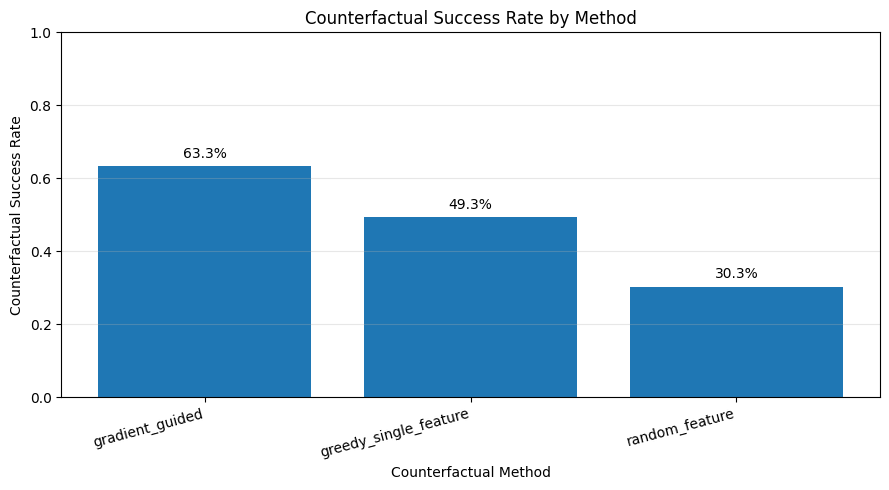

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

plot_data = cf_summary.set_index("method")["success_rate"]

bars = ax.bar(
    plot_data.index,
    plot_data.values
)

ax.set_ylim(0, 1)
ax.set_ylabel("Counterfactual Success Rate")
ax.set_xlabel("Counterfactual Method")
ax.set_title("Counterfactual Success Rate by Method")

ax.bar_label(
    bars,
    labels=[f"{v:.1%}" for v in plot_data.values],
    padding=4
)

ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

###17.2 — ROC curves
This is an important standard ML evaluation plot. It compares how well Logistic Regression, Random Forest, and MLP distinguish between patients who survived and those who died, across different classification thresholds.

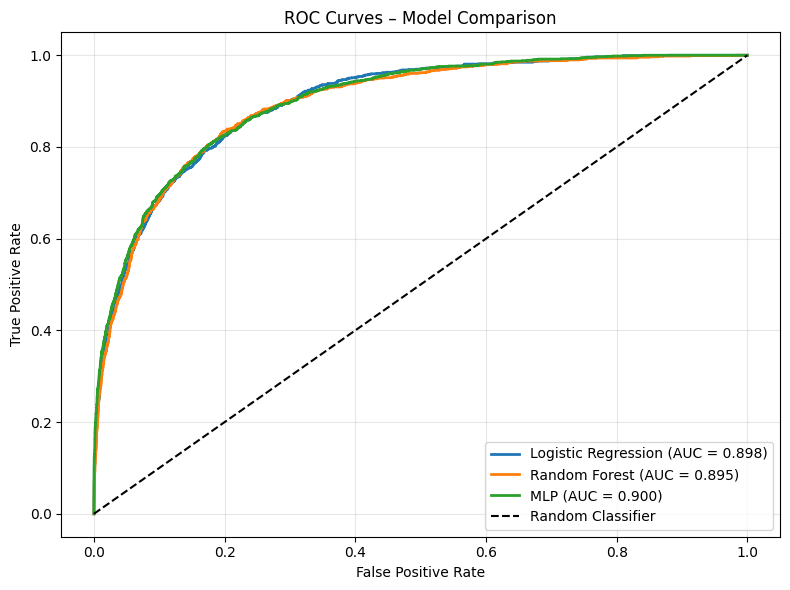

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

model_names = {
    "LogisticRegression": "Logistic Regression",
    "RandomForest": "Random Forest",
    "MLP": "MLP"
}

fig, ax = plt.subplots(figsize=(8, 6))

for key, label in model_names.items():
    probabilities = family_test_probs[key]

    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)

    ax.plot(fpr, tpr, linewidth=2, label=f"{label} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", label="Random Classifier")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves – Model Comparison")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

###17.3 Precision–Recall curves
This is especially important because your dataset is imbalanced (only around 8.6% mortality cases). PR curves show the trade-off between precision and recall for the positive class.

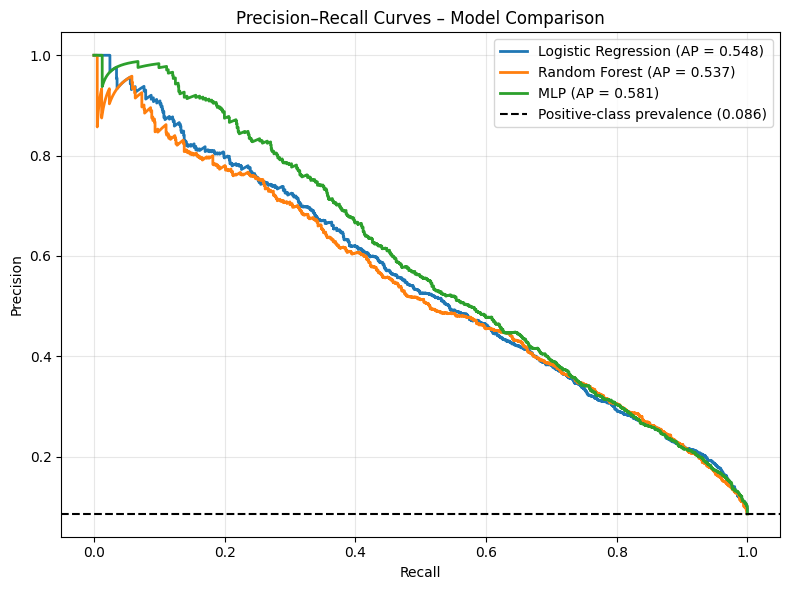

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(8, 6))

for key, label in model_names.items():
    probabilities = family_test_probs[key]

    precision, recall, _ = precision_recall_curve(
        y_test, probabilities
    )
    ap = average_precision_score(y_test, probabilities)

    ax.plot(recall, precision, linewidth=2,
            label=f"{label} (AP = {ap:.3f})")

baseline = np.mean(y_test)

ax.axhline(
    baseline,
    linestyle="--",
    color="black",
    label=f"Positive-class prevalence ({baseline:.3f})"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Curves – Model Comparison")
ax.legend(loc="best")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 17.4 Confusion Matrix

The confusion matrix evaluates the selected MLP model at its validation-selected decision threshold. It displays true positives, true negatives, false positives, and false negatives for ICU mortality prediction.

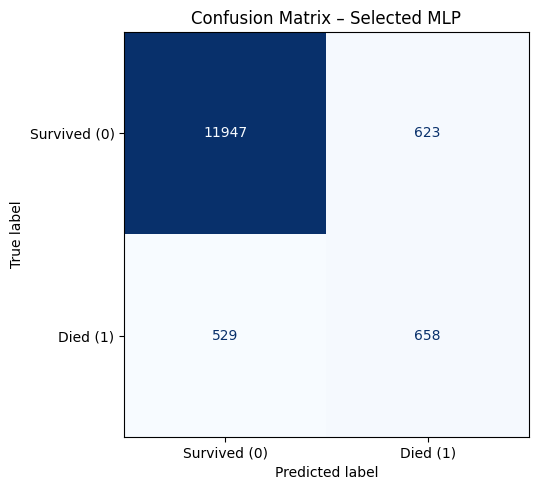

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

mlp_predictions = (test_prob >= LOCKED_THRESHOLD).astype(int)

cm = confusion_matrix(y_test, mlp_predictions)

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Survived (0)", "Died (1)"]
)

disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)

ax.set_title("Confusion Matrix – Selected MLP")
plt.tight_layout()
plt.show()

### 17.5 Calibration Curves

Calibration curves compare predicted probabilities with observed mortality rates. A well-calibrated model should produce probabilities that closely match the actual outcome frequencies.

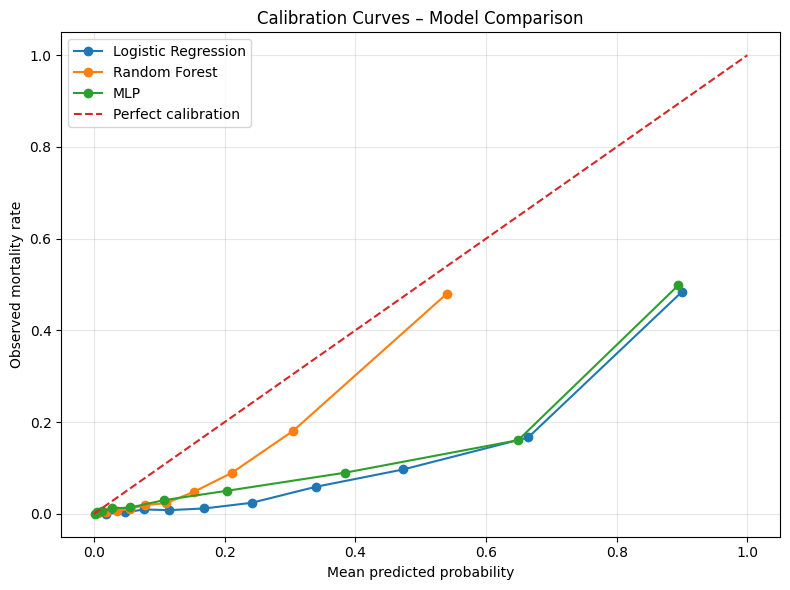

In [ ]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(8, 6))

for key, label in model_names.items():
    fraction_positive, mean_predicted = calibration_curve(
        y_test,
        family_test_probs[key],
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=label
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed mortality rate")
ax.set_title("Calibration Curves – Model Comparison")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 17.6 Counterfactual Cost Distribution

This plot compares the distribution of counterfactual costs across the three methods, considering only successful counterfactuals. Lower costs indicate smaller changes to the original patient features.

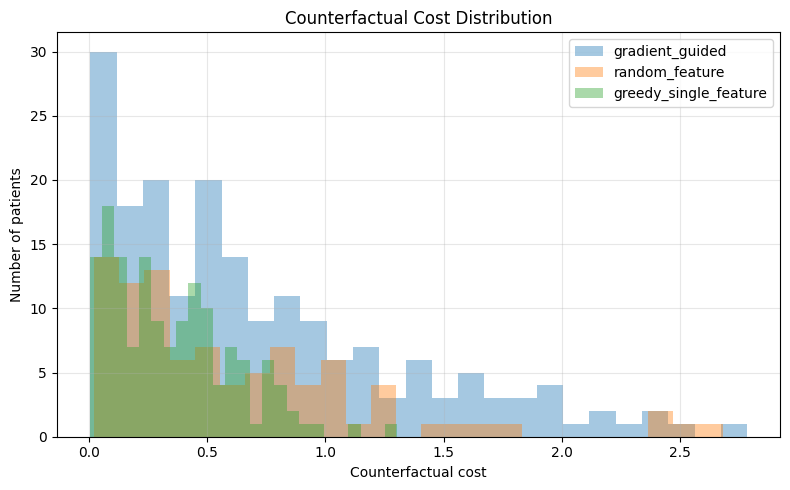

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

successful_cf = cf_results[cf_results["success"] == True]

for method in METHODS:
    values = successful_cf.loc[
        successful_cf["method"] == method, "cost"
    ].dropna()

    ax.hist(values, bins=25, alpha=0.4, label=method)

ax.set_xlabel("Counterfactual cost")
ax.set_ylabel("Number of patients")
ax.set_title("Counterfactual Cost Distribution")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 17.7 Changed-Feature Count Distribution

This plot compares how many features each method changes when generating successful counterfactuals. Fewer changed features indicate a more sparse counterfactual explanation.

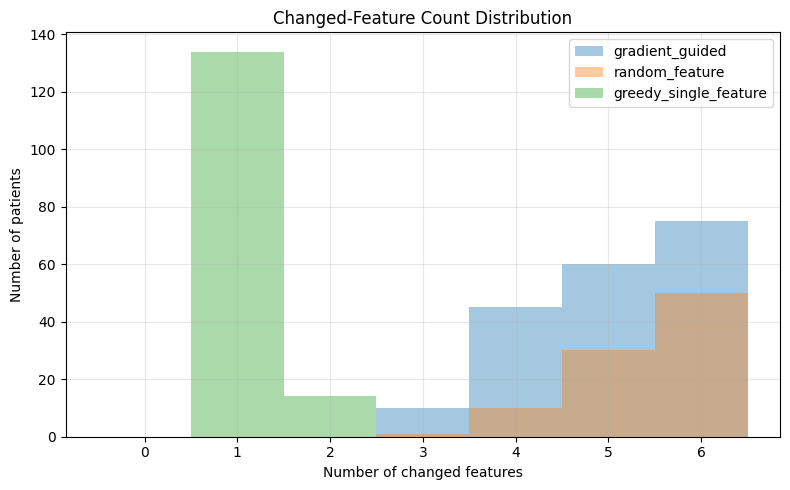

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

successful_cf = cf_results[cf_results["success"] == True]

for method in METHODS:
    values = successful_cf.loc[
        successful_cf["method"] == method,
        "n_changed_features"
    ].dropna()

    ax.hist(values, bins=range(0, int(values.max()) + 2),
            alpha=0.4, label=method, align="left")

ax.set_xlabel("Number of changed features")
ax.set_ylabel("Number of patients")
ax.set_title("Changed-Feature Count Distribution")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 17.8 Nearest-Neighbour Distance Distribution

This plot compares the distance between generated counterfactuals and their nearest training patients. It provides a diagnostic of how close the generated examples are to observed training data. Smaller distances may indicate better proximity to known patient examples, but do not prove clinical plausibility.

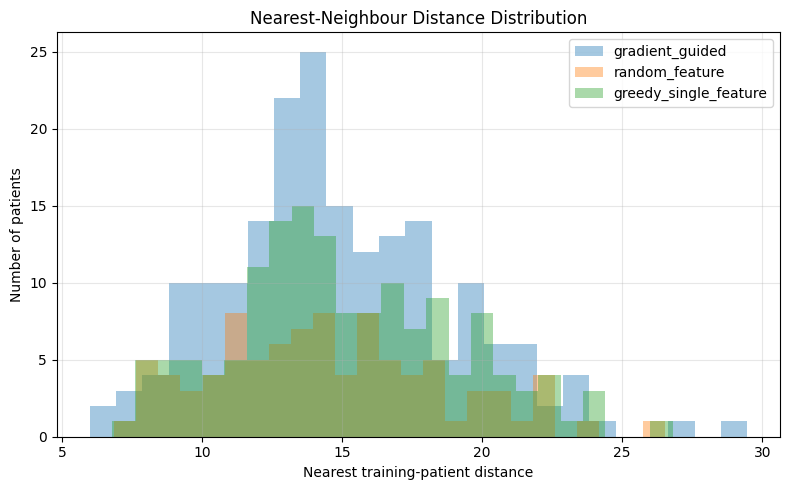

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

successful_cf = cf_results[cf_results["success"] == True]

for method in METHODS:
    values = successful_cf.loc[
        successful_cf["method"] == method,
        "nearest_train_distance"
    ].dropna()

    ax.hist(values, bins=25, alpha=0.4, label=method)

ax.set_xlabel("Nearest training-patient distance")
ax.set_ylabel("Number of patients")
ax.set_title("Nearest-Neighbour Distance Distribution")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 17.9 Stability Across Random Seeds

This plot shows the distribution of Jaccard similarity between changed-feature sets across different model seeds. Higher values indicate greater consistency in the features selected by the counterfactual method.

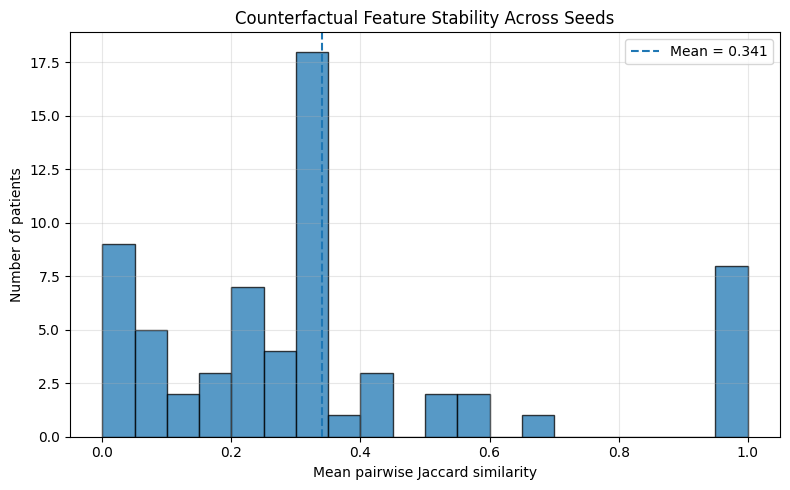

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

jaccard_values = stability_results[
    "mean_pairwise_jaccard"
].dropna()

ax.hist(jaccard_values, bins=20, edgecolor="black", alpha=0.75)

ax.axvline(
    jaccard_values.mean(),
    linestyle="--",
    label=f"Mean = {jaccard_values.mean():.3f}"
)

ax.set_xlabel("Mean pairwise Jaccard similarity")
ax.set_ylabel("Number of patients")
ax.set_title("Counterfactual Feature Stability Across Seeds")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 17.10 Counterfactual Probability Before vs After

This visualization compares the predicted mortality probabilities of patients before and after counterfactual generation. Only successful counterfactuals are considered. It demonstrates whether the generated feature changes reduce the model's predicted mortality risk below the selected decision threshold.

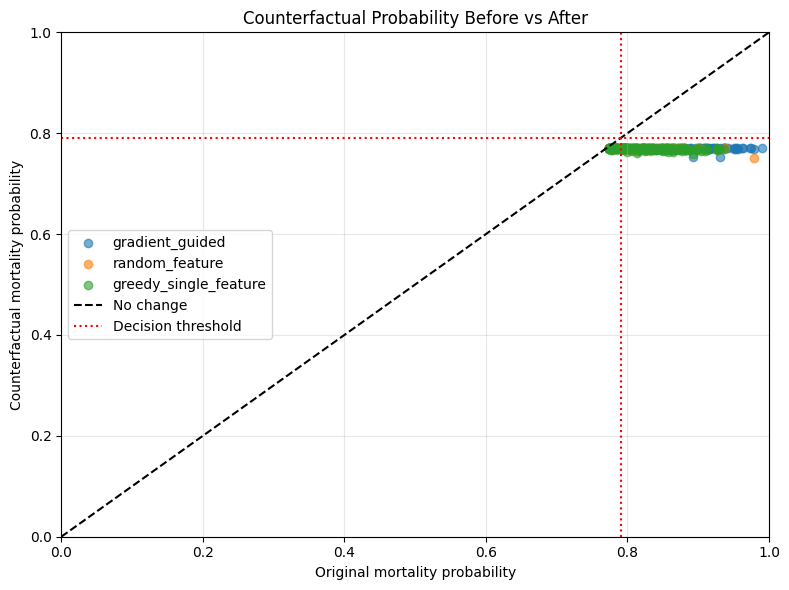

In [191]:
fig, ax = plt.subplots(figsize=(8, 6))

successful_cf = cf_results[cf_results["success"] == True]

for method in METHODS:
    subset = successful_cf[successful_cf["method"] == method]

    ax.scatter(
        subset["original_probability"],
        subset["counterfactual_probability"],
        alpha=0.6,
        label=method
    )

# Reference line: no change in probability
ax.plot([0, 1], [0, 1], "k--", label="No change")

# Selected decision threshold
ax.axhline(
    LOCKED_THRESHOLD,
    color="red",
    linestyle=":",
    label="Decision threshold"
)

ax.axvline(
    LOCKED_THRESHOLD,
    color="red",
    linestyle=":"
)

ax.set_xlabel("Original mortality probability")
ax.set_ylabel("Counterfactual mortality probability")
ax.set_title("Counterfactual Probability Before vs After")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 17.11 Paired Success-Rate Differences with 95% Confidence Intervals

This plot compares the differences in counterfactual success rates between methods using paired bootstrap confidence intervals. It helps assess whether the observed differences in success rates are statistically distinguishable from zero.

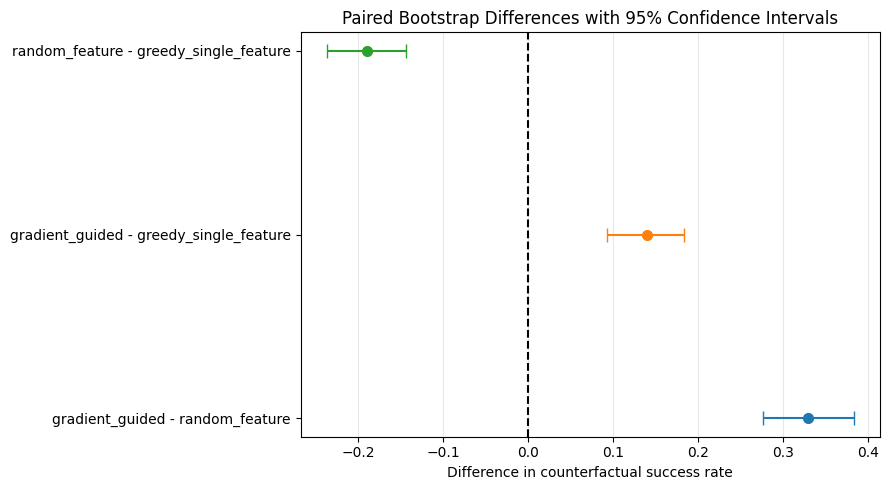

In [192]:
comparisons = [
    "gradient_guided - random_feature",
    "gradient_guided - greedy_single_feature",
    "random_feature - greedy_single_feature"
]

differences = [0.33, 0.14, -0.19]

lower_ci = [0.276667, 0.093333, -0.236667]
upper_ci = [0.383333, 0.183333, -0.143333]

y_pos = np.arange(len(comparisons))

fig, ax = plt.subplots(figsize=(9, 5))

for i in range(len(comparisons)):
    ax.errorbar(
        differences[i],
        y_pos[i],
        xerr=[[
            differences[i] - lower_ci[i]
        ], [
            upper_ci[i] - differences[i]
        ]],
        fmt="o",
        capsize=5,
        markersize=7
    )

ax.axvline(0, color="black", linestyle="--")
ax.set_yticks(y_pos)
ax.set_yticklabels(comparisons)
ax.set_xlabel("Difference in counterfactual success rate")
ax.set_title("Paired Bootstrap Differences with 95% Confidence Intervals")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## 18. Export audit trail and run manifest

In [194]:
export=cf_results.copy()
export["changed_features"]=export["changed_features"].apply(json.dumps)
export.to_csv(OUT/"counterfactual_case_results.csv",index=False)
cf_summary.to_csv(OUT/"counterfactual_method_summary.csv",index=False)
cf_pairwise.to_csv(OUT/"counterfactual_paired_bootstrap.csv",index=False)
family_metrics.to_csv(OUT/"test_model_family_metrics.csv",index=False)
paired_model_bootstrap.to_csv(OUT/"paired_model_bootstrap.csv",index=False)
family_pr_auc_ci.to_csv(OUT/"model_family_pr_auc_ci.csv",index=False)
stability_results.to_csv(OUT/"counterfactual_stability.csv",index=False)

manifest={
    "dataset":"WiDS Datathon 2020 ICU mortality",
    "target":TARGET,
    "split":"stratified 70/15/15; random_state=42",
    "selected_model":selected_name,
    "selection_metric":"validation PR-AUC",
    "locked_threshold":LOCKED_THRESHOLD,
    "counterfactual_methods":METHODS,
    "requested_counterfactual_cases":N_CF_CASES,
    "actual_counterfactual_cases":len(cf_sample),
    "mutable_features":mutable,
    "detected_min_max_pairs":pairs,
    "stability_seeds":STABILITY_SEEDS,
    "python":sys.version,
    "platform":platform.platform(),
    "torch":torch.__version__ if TORCH_AVAILABLE else None,
    "warning":"Counterfactual explanations are not clinical interventions."
}
with open(OUT/"run_manifest.json","w") as f: json.dump(manifest,f,indent=2,default=str)
print("Saved to:",OUT.resolve())

Saved to: /content/icu_counterfactual_outputs


## 19. Limitations and Final Remarks



### 19.1 Limitations

1. **Predictive limitations:** High predictive performance does not necessarily establish clinical utility or demonstrate causal relationships.

2. **Counterfactual interpretation:** Generated counterfactuals explain how changes in input features affect the model's prediction. They should not be interpreted as treatment recommendations or evidence that changing those features would improve patient outcomes.

3. **Plausibility limitations:** Nearest-neighbour distance is sensitive to high dimensionality, feature scaling, correlated measurements, and categorical sparsity. A small distance alone does not guarantee clinical plausibility.

4. **Feature constraints:** The detected minimum–maximum feature pairs capture only selected mathematical relationships and do not represent a complete physiological model. Similarly, percentile-based feature bounds do not guarantee realistic combinations of features.

5. **Optimization limitations:** Counterfactual generation depends on the selected mutable features, optimization parameters, search budget, and target probability. Different settings may produce different counterfactual solutions.

6. **Stability limitations:** Similar counterfactual success rates across model seeds do not necessarily imply that the same features will be selected. The observed feature-level stability indicates that explanations may vary across model initializations.

7. **Dataset limitations:** The study uses the WiDS Datathon 2020 dataset. Its findings may not generalize to other hospitals, patient populations, or clinical settings. Although no patient overlap was detected across the dataset splits, generalizability to independent clinical populations remains to be established.

8. **Model-specific limitations:** The gradient-guided approach relies on differentiable model inputs and is implemented using the selected MLP. It cannot be directly applied to non-differentiable models such as Random Forest without an alternative feature-selection or optimization strategy.

### 19.2 Final Remarks

This project developed and evaluated an ICU mortality prediction framework using Logistic Regression, Random Forest, and a Multi-Layer Perceptron. The models were compared using classification and probability-based evaluation metrics, with the MLP selected based on its validation performance.

The counterfactual study extended the prediction task by investigating whether small, constrained changes to input features could move high-risk predictions below the selected decision threshold. Three approaches—gradient-guided, random-feature, and greedy single-feature—were evaluated on the same held-out test cases.

The gradient-guided approach achieved the highest counterfactual success rate among the evaluated methods, with 63.33% success, compared with 49.33% for greedy single-feature search and 30.33% for random-feature search.

Paired bootstrap comparisons supported the observed differences in success rates. Constraint audits found no newly introduced percentile-bound or minimum–maximum violations in the evaluated cases. Stability analysis showed similar success rates across model seeds, although feature-level explanations varied.

Overall, the results demonstrate the potential of gradient-guided counterfactual search as a model-explanation technique. However, the generated counterfactuals describe changes in model predictions rather than guaranteed changes in patient outcomes. Further clinical validation is necessary before such explanations can be considered in real-world healthcare settings.